# Entrega 3 · Modelado del ganador de partidos de CS2
**Ciencia de Datos · UTN FRM · Comisión 5K10 · Grupo 07**

**Integrantes:** Berducci Nicolás · Genaulaz Martin · Yanardi Tomás · Yanardi Juan Cruz · Gallardo Federico · León Mario.

Queremos predecir, **antes de que empiece una serie**, cuál de los dos equipos la va a ganar. Cada fila es una serie completa, no un mapa ni un jugador. `target_team_a_won = 1` si ganó A y `0` si ganó B. A es el equipo con menor ID: no es local ni favorito.

El notebook corre completo de arriba hacia abajo, con `SEMILLA = 42` definida al principio y pasada a todo lo que la acepta.

## 0. Qué retomamos y qué cambia desde la Entrega 2

### Lo que nos corrigieron

**El dataset.** En la Entrega 2 nuestro dataset no tenía features agregadas: las columnas eran las mismas del Bronze, sin ningún cálculo. Lo que correspondía era un Silver mucho más trabajado, casi «goldificado», con variables calculadas a partir de los partidos anteriores de cada equipo. Corregimos el DAG. Ahora cada fila es una serie y sus estadísticas se calculan solo con partidos que terminaron antes de su inicio: Elo, winrates de 5, 10 y 20 partidos, KD, KDA, rating, ADR, mapas y rondas ganadas, rendimiento en el mismo formato y en el mismo tier, días de descanso, actividad en los últimos 7 y 30 días, estabilidad de la alineación, enfrentamientos directos (H2H) y ranking previo, además de la diferencia A−B de cada una. Con estas correcciones el dataset quedó en **43.719 partidos y 113 columnas**.

**La matriz de correlación.** La agregamos a pedido del profesor para detectar columnas redundantes. Usamos la correlación de Spearman: cuando dos columnas tenían |ρ| ≥ 0,8, nos quedamos con la que mejor separaba al target y sacamos la otra.

### De 113 a 27 columnas

Después de revisar la matriz de correlación y las hipótesis de la Entrega 2, nos quedaron **27 columnas**:

| Paso | Qué sale | Salen | Quedan |
|---|---|---|---|
| Silver corregido | — | — | 113 |
| No son predictores | 12 de identificación y contexto (IDs, nombres, fecha, torneo, etapa, versión del juego), el objetivo, 3 del resultado del propio partido (fin y mapas ganados: serían fuga) y 2 códigos de país | 18 | 95 |
| Calidad de datos | Familia KAST: tiene valores cero en partidos con kills | 5 | 90 |
| Diferencias A−B | Valores individuales de A y B, ya resumidos en su diferencia | 32 | 58 |
| Hipótesis | H1, descanso (3); H3, winrate de 10 (1); H4, antigüedad del ranking (1) | 5 | 53 |
| Columnas idénticas | Contadores exactamente iguales a otro contador | 6 | 47 |
| Matriz de correlación | 6 contadores que son fórmula directa de `matches_prior` y 14 columnas con \|ρ\| ≥ 0,8 | 20 | 27 |

### Cierre de la Entrega 2: las 27 columnas que quedaron

Son 25 numéricas más `bo_type` y `tier`. A los dos `matches_prior` les aplicamos `log1p`, por su asimetría. Con estas 27 columnas arranca el modelado.

| # | Columna | Qué mide |
|---|---|---|
| 1 | `bo_type` | Formato de la serie: BO1, BO2, BO3 o BO5. |
| 2 | `tier` | Nivel del torneo según Bo3.gg: s, a, b, c o d. |
| 3 | `elo_advantage_a` | Elo de A menos Elo de B, antes del partido. |
| 4 | `ranking_score_advantage_a` | Puntaje de ranking de A menos el de B, en el último ranking anterior al partido. |
| 5 | `round_winrate_last20_advantage_a` | % de rondas ganadas en los últimos 20 partidos, A menos B. |
| 6 | `form_last5_advantage_a` | % de victorias en los últimos 5 partidos, A menos B. |
| 7 | `same_bo_winrate_last20_advantage_a` | % de victorias en partidos del mismo formato (dentro de los últimos 20), A menos B. |
| 8 | `same_tier_winrate_last20_advantage_a` | % de victorias en partidos del mismo tier (dentro de los últimos 20), A menos B. |
| 9 | `lineup_stability_last5_advantage_a` | Cuánto se mantuvo la alineación en los últimos 5 partidos (de 0 a 1), A menos B. |
| 10 | `h2h_team_a_winrate_last5` | % de victorias de A en los últimos 5 cruces contra B. |
| 11 | `h2h_last5_count` | Cuántos cruces previos entre los dos se usaron (de 0 a 5). |
| 12 | `team_a_matches_prior` | Partidos anteriores registrados de A (entra con `log1p`). |
| 13 | `team_b_matches_prior` | Partidos anteriores registrados de B (entra con `log1p`). |
| 14 | `team_a_form_trend_5v5` | Tendencia de A: % de victorias de los últimos 5 menos el de los 5 anteriores. |
| 15 | `team_b_form_trend_5v5` | Tendencia de B: % de victorias de los últimos 5 menos el de los 5 anteriores. |
| 16 | `team_a_matches_last7d` | Partidos que jugó A en los últimos 7 días. |
| 17 | `team_b_matches_last7d` | Partidos que jugó B en los últimos 7 días. |
| 18 | `team_a_matches_last30d` | Partidos que jugó A en los últimos 30 días. |
| 19 | `team_b_matches_last30d` | Partidos que jugó B en los últimos 30 días. |
| 20 | `team_a_kda_last20_count` | Partidos de A con KDA válido dentro de los últimos 20. |
| 21 | `team_b_kda_last20_count` | Partidos de B con KDA válido dentro de los últimos 20. |
| 22 | `team_a_same_bo_winrate_last20_count` | Partidos de A del mismo formato dentro de los últimos 20. |
| 23 | `team_b_same_bo_winrate_last20_count` | Partidos de B del mismo formato dentro de los últimos 20. |
| 24 | `team_a_same_tier_winrate_last20_count` | Partidos de A del mismo tier dentro de los últimos 20. |
| 25 | `team_b_same_tier_winrate_last20_count` | Partidos de B del mismo tier dentro de los últimos 20. |
| 26 | `team_a_lineup_stability_last5_count` | Comparaciones de alineación disponibles para A (de 0 a 4). |
| 27 | `team_b_lineup_stability_last5_count` | Comparaciones de alineación disponibles para B (de 0 a 4). |

## 1. Configuración y funciones

Fijamos la semilla y los parámetros, y definimos las funciones que usamos en todo el notebook. `armar`, `medir` y `tabla_de` son las de la Práctica 2, adaptadas a nuestro dataset. Las métricas, la validación cruzada y la búsqueda de hiperparámetros salen de scikit-learn.

In [ ]:
import platform
from pathlib import Path
from collections import defaultdict
import hashlib, importlib.util, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import altair as alt
import sklearn
from IPython.display import display, HTML
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV, ParameterGrid
from sklearn.metrics import (accuracy_score, f1_score, recall_score, make_scorer,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix, brier_score_loss, log_loss)
from sklearn.inspection import permutation_importance

SEMILLA = 42
N_SPLITS = 5
N_JOBS = 6
CORTE_TEST = pd.Timestamp('2026-03-01', tz='UTC')   # Mismo corte de la Entrega 2.
UMBRAL = 0.50
ARCHIVO = Path('matches_latest.csv')
DRIVE_ID = '1l3o2EA1VHUgKmjWHILXWLfbFlCsFraqG'
SHA256_ESPERADO = '7bb158fa8f7f27f8318270a772d45fca7ed930dc187907507ea84b0584136fa5'
np.random.seed(SEMILLA)

pd.set_option('display.max_columns', None)   # Mostramos todas las columnas de cada tabla.
pd.set_option('display.max_colwidth', None)  # Mostramos el texto completo de cada celda, sin cortarlo con «...».
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110, 'font.size': 10})

print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__)

python 3.12.14 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1


In [ ]:
CATEGORICAS = ['bo_type', 'tier']
HISTORIA = ['team_a_matches_prior', 'team_b_matches_prior']

# Métrica principal: accuracy. Las otras tres son de control.
SCORING = {
    'accuracy': 'accuracy',
    'f1_macro': make_scorer(f1_score, average='macro'),
    'recall_A': make_scorer(recall_score, pos_label=1),
    'recall_B': make_scorer(recall_score, pos_label=0),
}

def armar(clasificador, columnas, usar_log=True):
    """Pipeline completo: elegir columnas -> preparar -> clasificar (armar de la Práctica 2)."""
    historia = [c for c in columnas if c in HISTORIA]
    categoricas = [c for c in columnas if c in CATEGORICAS]
    numericas = [c for c in columnas if c not in HISTORIA + CATEGORICAS]
    log = [('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one'))] if usar_log else []
    preparar = ColumnTransformer([
        ('numericas', Pipeline([
            ('imputar', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
            ('escalar', StandardScaler())]), numericas),
        ('historia', Pipeline(log + [('escalar', StandardScaler())]), historia),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas),
    ])  # Las columnas que no están en la lista quedan afuera.
    return Pipeline([('preparar', preparar), ('clasificador', clone(clasificador))])

def medir(pipeline, X, y, cv):
    """cross_validate con media y desvío, como en la Práctica 2."""
    r = cross_validate(pipeline, X, y, cv=cv, scoring=SCORING, n_jobs=N_JOBS,
                       return_train_score=True, error_score='raise')
    resumen = {'accuracy': r['test_accuracy'].mean(), 'desvío': r['test_accuracy'].std(),
               'accuracy train': r['train_accuracy'].mean(), 'f1 macro': r['test_f1_macro'].mean(),
               'recall A': r['test_recall_A'].mean(), 'recall B': r['test_recall_B'].mean()}
    return resumen, r

def tabla_de(busqueda):
    """Tabla completa de la grilla: todas las combinaciones, no solo la mejor."""
    r = pd.DataFrame(busqueda.cv_results_)
    cols = [c for c in r if c.startswith('param_')]
    cols += ['mean_test_accuracy', 'std_test_accuracy', 'mean_train_accuracy', 'mean_test_f1_macro',
             'mean_test_recall_A', 'mean_test_recall_B', 'rank_test_accuracy']
    return r[cols].sort_values('rank_test_accuracy', kind='stable')

def metricas(y, pred):
    return {'accuracy': accuracy_score(y, pred), 'f1 macro': f1_score(y, pred, average='macro')}

def huella_archivo(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

# Pares A/B de cada diferencia del Silver. Solo se usan para auditar la sección 3.
SUFIJOS = ('elo', 'winrate_last10', 'winrate_last20', 'form_last5', 'kda_last20', 'kd_last20',
           'rating_last20', 'adr_last20', 'map_winrate_last20', 'round_winrate_last20',
           'same_bo_winrate_last20', 'same_tier_winrate_last20', 'rest_days', 'lineup_stability_last5')
PARES = {s + '_advantage_a': ('team_a_' + s, 'team_b_' + s) for s in SUFIJOS}
PARES.update({'rank_advantage_a': ('team_b_rank', 'team_a_rank'),  # Puesto: menor es mejor, por eso B − A.
              'ranking_score_advantage_a': ('team_a_ranking_score', 'team_b_ranking_score'),
              'round_diff_last20_advantage_a': ('team_a_round_diff_per_match_last20',
                                                'team_b_round_diff_per_match_last20')})

def construir_cv_temporal(datos, n_splits=5):
    """TimeSeriesSplit sobre calendario diario, luego mapeado a partidos.

    Los bloques de validación tienen igual duración de calendario (salvo el
    resto inicial), aunque distinta cantidad de partidos. Purgamos etiquetas
    que no se conocían al inicio del bloque. No barajamos ni estratificamos.
    """
    inicio = datos['start_at_utc']
    fin = datos['end_at_utc']
    calendario = pd.date_range(inicio.min().floor('D'), inicio.max().floor('D'), freq='D')
    cv, filas = [], []
    for k, (dias_e, dias_v) in enumerate(TimeSeriesSplit(n_splits=n_splits).split(calendario), 1):
        limite = calendario[dias_v[0]]
        hasta = calendario[dias_v[-1]] + pd.Timedelta(days=1)
        anteriores = inicio.lt(limite)
        disponibles = fin.notna() & fin.lt(limite)
        e = np.flatnonzero((anteriores & disponibles).to_numpy())
        v = np.flatnonzero((inicio.ge(limite) & inicio.lt(hasta)).to_numpy())
        if not len(e) or not len(v):
            raise ValueError('Un fold temporal quedó vacío; revisar el calendario.')
        if datos.iloc[e]['target_team_a_won'].nunique() != 2 or datos.iloc[v]['target_team_a_won'].nunique() != 2:
            raise ValueError('Un fold no contiene ambas clases; revisar el esquema temporal.')
        assert inicio.iloc[e].max() < inicio.iloc[v].min()
        assert fin.iloc[e].max() < limite
        assert not set(datos.iloc[e].match_id) & set(datos.iloc[v].match_id)
        cv.append((e, v))
        filas.append({'fold': k, 'train desde': inicio.iloc[e].min(),
                      'train hasta': inicio.iloc[e].max(), 'validación desde': limite,
                      'validación hasta (excl.)': hasta, 'n train': len(e), 'n validación': len(v),
                      'purgados': int((anteriores & ~disponibles).sum()),
                      '% A train': 100*datos.iloc[e].target_team_a_won.mean(),
                      '% A validación': 100*datos.iloc[v].target_team_a_won.mean()})
    return cv, pd.DataFrame(filas)

def auditar_derivadas(datos):
    filas = []
    for nombre, (a, b) in PARES.items():
        esperado = datos[a] - datos[b]
        correcto = np.isclose(datos[nombre], esperado, rtol=1e-8, atol=1e-8, equal_nan=True)
        filas.append({'derivada': nombre, 'fórmula': f'{a} - {b}',
                      'filas verificadas': len(datos), 'diferencias': int((~correcto).sum())})
    return pd.DataFrame(filas)

def auditar_historia_resultados(datos):
    """Reconstrucción independiente de Elo, winrates y H2H desde resultados.

    No reconstruye mecánicas/rondas/alineaciones: el CSV no contiene su Bronze.
    Usa únicamente resultados con fin conocido estrictamente anterior al inicio.
    """
    filas = datos.sort_values(['start_at_utc', 'match_id']).to_dict('records')
    completos = sorted((r for r in filas if pd.notna(r['end_at_utc'])),
                       key=lambda r: (r['end_at_utc'], r['match_id']))
    historial, elo, h2h = defaultdict(list), defaultdict(lambda: 1500.0), defaultdict(list)
    errores, maximos = defaultdict(int), defaultdict(float)
    j = 0
    def comparar(c, real, esperado):
        if not np.isclose(real, esperado, rtol=1e-7, atol=1e-7, equal_nan=True):
            errores[c] += 1
        else:
            errores.setdefault(c, 0)
        if pd.notna(real) and pd.notna(esperado):
            maximos[c] = max(maximos[c], abs(float(real)-float(esperado)))
    for r in filas:
        while j < len(completos) and completos[j]['end_at_utc'] < r['start_at_utc']:
            p = completos[j]
            a, b, y = p['team_a_id'], p['team_b_id'], p['target_team_a_won']
            delta = 32 * (y - 1/(1+10**((elo[b]-elo[a])/400)))
            elo[a] += delta
            elo[b] -= delta
            historial[a].append((p['end_at_utc'], y))
            historial[b].append((p['end_at_utc'], 1-y))
            h2h[(min(a,b), max(a,b))].append(a if y else b)
            j += 1
        for lado in ('a', 'b'):
            equipo = r[f'team_{lado}_id']
            h = historial[equipo]
            pref = f'team_{lado}_'
            comparar(pref+'matches_prior', r[pref+'matches_prior'], len(h))
            comparar(pref+'elo', r[pref+'elo'], elo[equipo])
            for n, suf in [(5, 'form_last5'), (10, 'winrate_last10'), (20, 'winrate_last20')]:
                ventana = h[-n:]
                esperado = np.mean([v[1] for v in ventana]) if len(ventana)>=5 else np.nan
                comparar(pref+suf, r[pref+suf], esperado)
                comparar(pref+suf+'_count', r[pref+suf+'_count'], len(ventana))
            tendencia = (np.mean([v[1] for v in h[-5:]]) - np.mean([v[1] for v in h[-10:-5]])) if len(h)>=10 else np.nan
            comparar(pref+'form_trend_5v5', r[pref+'form_trend_5v5'], tendencia)
            descanso = (r['start_at_utc']-h[-1][0]).total_seconds()/86400 if h else np.nan
            comparar(pref+'rest_days', r[pref+'rest_days'], descanso)
        a, b = r['team_a_id'], r['team_b_id']
        previos = h2h[(min(a,b),max(a,b))][-5:]
        comparar('h2h_last5_count', r['h2h_last5_count'], len(previos))
        esperado = np.mean([v==a for v in previos]) if previos else np.nan
        comparar('h2h_team_a_winrate_last5', r['h2h_team_a_winrate_last5'], esperado)
    return pd.DataFrame([{'columna': c, 'diferencias': n, 'máximo error absoluto': maximos[c]}
                         for c, n in errores.items()])


def parametros_cortos(parametros):
    return {k.replace('clasificador__', ''): v for k, v in parametros.items()}

## 2. Carga del Silver

Usamos la misma extracción de la Entrega 2. Verificamos su huella (SHA-256) para asegurarnos de que es exactamente el mismo archivo, y controlamos filas, columnas, clave y fechas antes de modelar.

In [ ]:
if not ARCHIVO.is_file() and 'google.colab' in sys.modules:
    if importlib.util.find_spec('gdown') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
    import gdown
    gdown.download(id=DRIVE_ID, output=str(ARCHIVO), quiet=False)
if not ARCHIVO.is_file():
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        candidato = carpeta / 'include/output/silver/matches_latest.csv'
        if candidato.is_file():
            ARCHIVO = candidato
            break
assert ARCHIVO.is_file(), 'Falta matches_latest.csv junto al notebook.'
assert huella_archivo(ARCHIVO) == SHA256_ESPERADO, 'No es la misma extracción de la Entrega 2.'

df = pd.read_csv(ARCHIVO, low_memory=False)
assert df.shape == (43719, 113)
assert df.match_id.is_unique
assert df.target_team_a_won.isin([0, 1]).all()
assert df.team_a_id.lt(df.team_b_id).all()
for c in ['start_at_utc', 'end_at_utc']:
    df[c] = pd.to_datetime(df[c], format='mixed', utc=True)
assert df.start_at_utc.notna().all()
df = df.sort_values(['start_at_utc', 'match_id'], kind='stable').reset_index(drop=True)
print(f'{len(df):,} partidos y {df.shape[1]} columnas, del {df.start_at_utc.min():%d/%m/%Y} al {df.start_at_utc.max():%d/%m/%Y}.')
print('Partidos sin hora de finalización:', df.end_at_utc.isna().sum())

43,719 partidos y 113 columnas, del 02/10/2023 al 15/10/2026.
Partidos sin hora de finalización: 4


## 3. Control de las variables calculadas

Antes de usar las columnas del Silver comprobamos dos cosas:

1. **Las restas.** Cada diferencia `_advantage_a` tiene que ser igual a la columna de A menos la de B (en el puesto de ranking, B menos A, porque menor es mejor).
2. **El historial.** Recalculamos desde cero, solo con los resultados, el Elo, los winrates de 5, 10 y 20, la tendencia, los días de descanso y el H2H. Para cada partido usamos únicamente series que terminaron **antes** de su inicio, y comparamos con lo que trae el Silver.

Las estadísticas mecánicas (KDA, rondas, alineaciones) no se pueden recalcular desde este CSV, porque necesitan el detalle del Bronze.

In [ ]:
tabla_derivadas = auditar_derivadas(df)
display(tabla_derivadas)
tabla_historia = auditar_historia_resultados(df)
display(tabla_historia)
assert tabla_derivadas['diferencias'].sum() == 0 and tabla_historia['diferencias'].sum() == 0

,derivada,fórmula,filas verificadas,diferencias
0,elo_advantage_a,team_a_elo - team_b_elo,43719,0
1,winrate_last10_advantage_a,team_a_winrate_last10 - team_b_winrate_last10,43719,0
2,winrate_last20_advantage_a,team_a_winrate_last20 - team_b_winrate_last20,43719,0
3,form_last5_advantage_a,team_a_form_last5 - team_b_form_last5,43719,0
4,kda_last20_advantage_a,team_a_kda_last20 - team_b_kda_last20,43719,0
5,kd_last20_advantage_a,team_a_kd_last20 - team_b_kd_last20,43719,0
6,rating_last20_advantage_a,team_a_rating_last20 - team_b_rating_last20,43719,0
7,adr_last20_advantage_a,team_a_adr_last20 - team_b_adr_last20,43719,0
8,map_winrate_last20_advantage_a,team_a_map_winrate_last20 - team_b_map_winrate_last20,43719,0
9,round_winrate_last20_advantage_a,team_a_round_winrate_last20 - team_b_round_winrate_last20,43719,0


,columna,diferencias,máximo error absoluto
0,team_a_matches_prior,0,0.000000e+00
1,team_a_elo,0,4.547474e-13
2,team_a_form_last5,0,0.000000e+00
3,team_a_form_last5_count,0,0.000000e+00
4,team_a_winrate_last10,0,5.551115e-17
5,team_a_winrate_last10_count,0,0.000000e+00
6,team_a_winrate_last20,0,1.110223e-16
7,team_a_winrate_last20_count,0,0.000000e+00
8,team_a_form_trend_5v5,0,5.551115e-17
9,team_a_rest_days,0,1.136868e-13


**Conclusión:** las 17 restas coinciden en las 43.719 filas, y el historial recalculado coincide en todas las columnas: 0 diferencias. Los errores máximos que aparecen son de redondeo, del orden de 10⁻¹³. Esto nos dice dos cosas:

1. Podemos usar las diferencias del Silver tal cual, sin recalcularlas.
2. El Elo y los winrates de cada partido se arman solo con resultados anteriores. No traen escondido el resultado del partido que queremos predecir.

## 4. Métrica y reglas de selección

**Métrica principal: accuracy**, el porcentaje de series acertadas. A y B son lados asignados por ID; equivocarse a favor de uno cuesta lo mismo que a favor del otro. Las clases están bastante parejas. Mostramos también F1 macro y recall de A y B para no esconder errores de una clase.

- Las cuatro familias prueban las mismas variantes de columnas y los mismos 5 folds temporales.
- Cada variante vuelve a buscar sus propios hiperparámetros. No descartamos una familia antes de ajustarla.
- Dentro de cada familia, elegimos la variante con menos columnas entre las que quedan a menos de un desvío del mejor promedio. Si tienen igual cantidad, elegimos mayor accuracy.
- Comparamos esos tres finalistas. Entre los que quedan a menos de un desvío del mejor, preferimos logística, árbol de decisión, bosque y boosting, en ese orden. Es una regla práctica de simplicidad, no una prueba de empate estadístico.
- El umbral queda en 0,50. El test no participa de ninguna elección.

## 5. Test reservado y validación cruzada temporal

Nuestras filas están ordenadas en el tiempo y queremos predecir partidos futuros. Por eso partimos por fecha: es la fila «en el tiempo» de la tabla de la consigna (`TimeSeriesSplit`).

- **Test:** todas las series que empiezan desde el 01/03/2026, el mismo corte de la Entrega 2. No se toca hasta la sección 11.
- **Entrenamiento:** las series que empezaron **y terminaron** antes del corte.
- **Purgados:** las que empezaron antes del corte pero no consta que hayan terminado antes. El 01/03 su resultado todavía no se conocía, así que no se pueden usar para entrenar; tampoco son test. Son 2 de 43.719 y no cambian ningún número: es para no entrenar con un resultado que todavía no existía.

Dentro del entrenamiento armamos 5 folds con `TimeSeriesSplit` sobre los días del calendario. Cada fold entrena con todo lo anterior y valida con el bloque siguiente, de unos 5 meses, con la misma purga.

No agrupamos por equipo. Queremos predecir partidos futuros de equipos que ya conocemos, así que un mismo equipo puede estar en entrenamiento y en validación. Lo que controlamos es el tiempo: nunca se entrena con partidos posteriores a los que se validan.

In [ ]:
antes = df.start_at_utc.lt(CORTE_TEST)
termino_antes = df.end_at_utc.notna() & df.end_at_utc.lt(CORTE_TEST)
train = df.loc[antes & termino_antes].reset_index(drop=True)
test = df.loc[~antes].reset_index(drop=True)
purgados = df.loc[antes & ~termino_antes, ['match_id', 'start_at_utc', 'end_at_utc']]

assert len(train) + len(test) + len(purgados) == len(df)
assert train.end_at_utc.max() < CORTE_TEST <= test.start_at_utc.min()
assert not set(train.match_id) & set(test.match_id)

cv, tabla_folds = construir_cv_temporal(train, N_SPLITS)
display(pd.DataFrame({'conjunto': ['entrenamiento', 'test', 'purgados'],
                      'series': [len(train), len(test), len(purgados)]}))
display(purgados)
display(tabla_folds)

,conjunto,series
0,entrenamiento,34898
1,test,8819
2,purgados,2


,match_id,start_at_utc,end_at_utc
28638,100557,2025-09-26 14:30:00+00:00,NaT
34850,112164,2026-02-28 05:54:15+00:00,2026-03-01 07:53:15+00:00


,fold,train desde,train hasta,validación desde,validación hasta (excl.),n train,n validación,purgados,% A train,% A validación
0,1,2023-10-02 21:00:00+00:00,2024-02-29 21:00:00+00:00,2024-03-01 00:00:00+00:00,2024-07-25 00:00:00+00:00,5191,6036,2,54.016567,52.833002
1,2,2023-10-02 21:00:00+00:00,2024-07-24 22:00:00+00:00,2024-07-25 00:00:00+00:00,2024-12-18 00:00:00+00:00,11221,6914,8,53.364228,52.386462
2,3,2023-10-02 21:00:00+00:00,2024-12-17 20:00:00+00:00,2024-12-18 00:00:00+00:00,2025-05-13 00:00:00+00:00,18141,5961,2,52.995976,53.497735
3,4,2023-10-02 21:00:00+00:00,2025-05-12 19:00:00+00:00,2025-05-13 00:00:00+00:00,2025-10-06 00:00:00+00:00,24101,4971,3,53.126426,53.952927
4,5,2023-10-02 21:00:00+00:00,2025-10-05 21:30:00+00:00,2025-10-06 00:00:00+00:00,2026-03-01 00:00:00+00:00,29071,5823,4,53.269581,53.666495


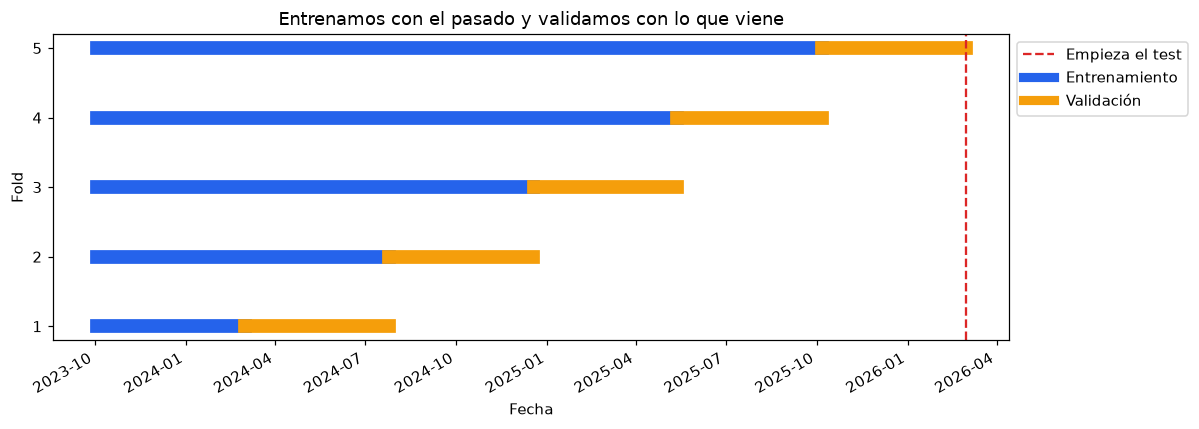

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4))
for k, (e, v) in enumerate(cv, 1):
    ax.plot([train.start_at_utc.iloc[e].min(), train.start_at_utc.iloc[e].max()], [k, k], lw=9, color='#2563eb')
    ax.plot([train.start_at_utc.iloc[v].min(), train.start_at_utc.iloc[v].max()], [k, k], lw=9, color='#f59e0b')
ax.axvline(CORTE_TEST, color='#dc2626', linestyle='--', label='Empieza el test')
ax.plot([], [], color='#2563eb', lw=6, label='Entrenamiento')
ax.plot([], [], color='#f59e0b', lw=6, label='Validación')
ax.set(yticks=range(1, N_SPLITS + 1), ylabel='Fold', xlabel='Fecha', title='Entrenamos con el pasado y validamos con lo que viene')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 6. Preparación dentro del pipeline

Todo lo que se le hace a los datos está dentro del pipeline. Así se vuelve a aprender en cada fold sin mirar la validación:

- **Numéricas:** imputamos con la mediana, agregamos un indicador de dato faltante y escalamos. Un faltante no es un cero: casi siempre significa que el equipo tenía menos de 5 partidos previos.
- **`matches_prior`:** `log1p` (decidido en la Entrega 2 por la asimetría) y escalado.
- **`bo_type` y `tier`:** one-hot. BO3 es un formato, no «tres veces BO1».

Usamos directamente las diferencias A−B que trae el Silver. En la sección 3 comprobamos que están bien calculadas, y una resta entre dos valores de la misma fila no aprende nada del resto de los datos, así que no genera fuga.

**La columna extra.** Además de las 27, X incluye `winrate_last20_advantage_a`, pero **no entra al modelo base**: solo la usamos en dos experimentos de la sección 8. La Entrega 2 la sacó por la correlación (es casi igual al winrate de rondas, que separaba mejor), pero tiene datos en más partidos: 82 % contra 74 %. Queremos ver si esa cobertura extra sirve.

In [ ]:
COLUMNAS_E2 = ['bo_type', 'tier', 'elo_advantage_a', 'ranking_score_advantage_a',
               'round_winrate_last20_advantage_a', 'form_last5_advantage_a',
               'same_bo_winrate_last20_advantage_a', 'same_tier_winrate_last20_advantage_a',
               'lineup_stability_last5_advantage_a', 'h2h_team_a_winrate_last5', 'h2h_last5_count',
               'team_a_matches_prior', 'team_b_matches_prior',
               'team_a_form_trend_5v5', 'team_b_form_trend_5v5',
               'team_a_matches_last7d', 'team_b_matches_last7d',
               'team_a_matches_last30d', 'team_b_matches_last30d',
               'team_a_kda_last20_count', 'team_b_kda_last20_count',
               'team_a_same_bo_winrate_last20_count', 'team_b_same_bo_winrate_last20_count',
               'team_a_same_tier_winrate_last20_count', 'team_b_same_tier_winrate_last20_count',
               'team_a_lineup_stability_last5_count', 'team_b_lineup_stability_last5_count']
EXTRA = 'winrate_last20_advantage_a'   # Solo para los experimentos de la sección 8.
assert len(set(COLUMNAS_E2)) == 27

X_train = train[COLUMNAS_E2 + [EXTRA]]
y_train = train.target_team_a_won
X_test = test[COLUMNAS_E2 + [EXTRA]]
y_test = test.target_team_a_won

clases = y_train.value_counts().sort_index().rename(index={0: 'gana B', 1: 'gana A'}).to_frame('series')
clases['%'] = (100 * clases.series / len(y_train)).round(1)
display(clases)
display(armar(LogisticRegression(max_iter=5000, random_state=SEMILLA), COLUMNAS_E2))

,series,%
target_team_a_won,,
gana B,16287,46.7
gana A,18611,53.3


Pipeline(steps=[('preparar',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('imputar',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['elo_advantage_a',
                                                   'ranking_score_advantage_a',
                                                   'round_winrate_last20_advantage_a',
                                                   'form_last5_advantage_a',
                                                   'same_bo_winrate_last20_advantage_...
                                                   'team_b_lineup_stability_last5_count']),
                                                 ('historia',
                                                  Pipeline(steps=[('log1p',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('escalar',
                                                                   StandardScaler())]),
                                                  ['team_a_matches_prior',
                                                   'team_b_matches_prior']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['bo_type', 'tier'])])),
                ('clasificador',
                 LogisticRegression(max_iter=5000, random_state=42))])

## 7. Piso, familias y grillas

El piso dice siempre la clase más frecuente. Para superarlo comparamos logística, árbol de decisión, random forest y gradient boosting, pero **cada uno con su propia grilla y sus variantes de columnas**.

| Familia | Qué variamos | Para qué |
|---|---|---|
| Logística | `C` y `class_weight` | Regularización y peso de las clases |
| Árbol de decisión | `max_depth`, `min_samples_leaf` y `class_weight` | Profundidad, tamaño mínimo de las hojas y peso de las clases |
| Random forest | `max_depth`, `min_samples_leaf`, `max_features` y `class_weight` | Complejidad de los árboles, diversidad y peso de las clases |
| Gradient boosting | `learning_rate`, `max_iter`, `max_leaf_nodes` y `l2_regularization` | Velocidad, cantidad de pasos, complejidad y regularización |

Las grillas son acotadas para poder ejecutar todo. El bosque usa 150 árboles. Desactivamos el corte temprano del boosting para que no reserve una validación interna al azar. Todo se evalúa con nuestros folds temporales.

In [ ]:
clasificadores = {
    'regresión logística': LogisticRegression(max_iter=5000, random_state=SEMILLA),
    'árbol de decisión': DecisionTreeClassifier(random_state=SEMILLA),
    'random forest': RandomForestClassifier(n_estimators=150, n_jobs=1, random_state=SEMILLA),
    'gradient boosting': HistGradientBoostingClassifier(early_stopping=False, random_state=SEMILLA),
}
grillas = {
    'regresión logística': {
        'clasificador__C': [0.01, 0.1, 1.0, 10.0],
        'clasificador__class_weight': [None, 'balanced'],
    },
    'árbol de decisión': {
        'clasificador__max_depth': [3, 4, 6, 8, 10, 14],
        'clasificador__min_samples_leaf': [1, 50, 200],
        'clasificador__class_weight': [None, 'balanced'],
    },
    'random forest': {
        'clasificador__max_depth': [6, 12],
        'clasificador__min_samples_leaf': [10, 30],
        'clasificador__max_features': ['sqrt', 0.7],
        'clasificador__class_weight': [None, 'balanced'],
    },
    'gradient boosting': {
        'clasificador__learning_rate': [0.05, 0.1],
        'clasificador__max_iter': [100, 200],
        'clasificador__max_leaf_nodes': [7, 15],
        'clasificador__l2_regularization': [0.0, 1.0],
    },
}

def sin(columnas):
    return [c for c in COLUMNAS_E2 if c not in columnas]

contadores = [c for c in COLUMNAS_E2 if c.endswith('_count')]
BASE = 'base (27 de la E2)'
variantes = {
    BASE: (COLUMNAS_E2, True),
    'sin Elo': (sin(['elo_advantage_a']), True),
    'sin ranking': (sin(['ranking_score_advantage_a']), True),
    'agregamos winrate 20': (COLUMNAS_E2 + [EXTRA], True),
    'winrate 20 en vez de rondas': ([EXTRA if c == 'round_winrate_last20_advantage_a' else c for c in COLUMNAS_E2], True),
    'sin H2H': (sin(['h2h_team_a_winrate_last5', 'h2h_last5_count']), True),
    'sin estabilidad': (sin([c for c in COLUMNAS_E2 if 'lineup_stability' in c]), True),
    'sin contadores': (sin(contadores), True),
    'historia sin log': (COLUMNAS_E2, False),
}
resumen_piso, resultados_piso = medir(
    armar(DummyClassifier(strategy='most_frequent'), COLUMNAS_E2), X_train, y_train, cv)
display(pd.DataFrame([resumen_piso], index=['piso']).round(4))

,accuracy,desvío,accuracy train,f1 macro,recall A,recall B
piso,0.5327,0.0057,0.5335,0.3475,1.0,0.0


In [ ]:
presupuesto = pd.DataFrame([
    {'familia': familia, 'combinaciones por variante': len(ParameterGrid(grillas[familia])),
     'variantes': len(variantes),
     'ajustes en los folds': len(ParameterGrid(grillas[familia])) * len(variantes) * len(cv)}
    for familia in clasificadores
]).set_index('familia')
display(presupuesto)
print('Total de ajustes de búsqueda:', presupuesto['ajustes en los folds'].sum())

Total de ajustes de búsqueda: 3420


,combinaciones por variante,variantes,ajustes en los folds
familia,,,
regresión logística,8,9,360
árbol de decisión,36,9,1620
random forest,16,9,720
gradient boosting,16,9,720


**Cómo leerlo:** por cada variante probamos 8 configuraciones de logística, 36 de árbol, 16 de bosque y 16 de boosting. Cada una se entrena en los 5 folds. Con 9 variantes son **3.420 ajustes de búsqueda**. El piso usa los mismos folds.

## 8. Columnas e hiperparámetros, en las cuatro familias

Cada familia prueba las mismas nueve variantes: base, sin Elo, sin ranking, sin H2H, sin estabilidad, sin contadores, agregar winrate de 20, reemplazar rondas por winrate de 20 e historia sin log. **Cada variante vuelve a buscar sus mejores hiperparámetros.**

En cada subsección mostramos la tabla de variantes, las grillas completas desplegables, una curva y su conclusión. La curva usa la variante elegida dentro de esa familia: cambia un parámetro, compara dos opciones y mantiene los demás fijos. Así no mezclamos configuraciones distintas en una misma línea.

In [ ]:
busquedas, resultados_variantes, tablas_completas, tablas_por_familia = {}, {}, {}, {}

def buscar_familia(familia):
    filas = []
    for nombre, (columnas, usar_log) in variantes.items():
        busqueda = GridSearchCV(
            armar(clasificadores[familia], columnas, usar_log), grillas[familia],
            scoring=SCORING, refit=False, cv=cv, n_jobs=N_JOBS,
            return_train_score=True, error_score='raise')
        busqueda.fit(X_train, y_train)
        r = busqueda.cv_results_
        indice = int(np.argmax(r['mean_test_accuracy']))
        resultados_variantes[familia, nombre] = np.array([
            r[f'split{k}_test_accuracy'][indice] for k in range(N_SPLITS)])
        d = resultados_variantes[familia, nombre] - resultados_variantes[familia, BASE]
        busquedas[familia, nombre] = busqueda
        tablas_completas[familia, nombre] = tabla_de(busqueda)
        filas.append({
            'variante': nombre, 'columnas': len(columnas),
            'accuracy': r['mean_test_accuracy'][indice], 'desvío': r['std_test_accuracy'][indice],
            'accuracy train': r['mean_train_accuracy'][indice],
            'f1 macro': r['mean_test_f1_macro'][indice],
            'recall A': r['mean_test_recall_A'][indice], 'recall B': r['mean_test_recall_B'][indice],
            'diferencia con base': d.mean(), 'desvío diferencia': d.std(),
            'folds que mejoran': int((d > 0).sum()), 'índice': indice,
            'parámetros': r['params'][indice],
        })
    return pd.DataFrame(filas).set_index('variante')

def elegir_variante(tabla):
    mejor = tabla.accuracy.idxmax()
    limite = tabla.loc[mejor, 'accuracy'] - tabla.loc[mejor, 'desvío']
    candidatas = tabla[tabla.accuracy >= limite]
    return candidatas.sort_values(['columnas', 'accuracy'],
                                  ascending=[True, False], kind='stable').index[0]

def mostrar_grillas(familia):
    from html import escape
    detalles = [f'<h4>{escape(nombre)}</h4>' + tablas_completas[familia, nombre].to_html(index=False)
                for nombre in variantes]
    display(HTML('<details><summary>Ver todas las combinaciones de la grilla</summary>'
                 + ''.join(detalles) + '</details>'))

def graficar_grilla(familia, eje, agrupar, nombres, etiqueta_eje, escala='linear'):
    tabla = tablas_por_familia[familia]
    variante = elegir_variante(tabla)
    parametros = tabla.loc[variante, 'parámetros']
    r = busquedas[familia, variante].cv_results_
    fijos = {k: v for k, v in parametros.items() if k not in [eje, agrupar]}
    fig, ax = plt.subplots(figsize=(10, 4))
    for valor, nombre, color in zip(grillas[familia][agrupar], nombres, ['#2563eb', '#dc2626']):
        indices = [i for i, p in enumerate(r['params'])
                   if p[agrupar] == valor and all(p[k] == v for k, v in fijos.items())]
        indices.sort(key=lambda i: r['params'][i][eje])
        x = [r['params'][i][eje] for i in indices]
        ax.plot(x, r['mean_train_accuracy'][indices], '--', color=color,
                label=f'entrenamiento, {nombre}')
        ax.errorbar(x, r['mean_test_accuracy'][indices], yerr=r['std_test_accuracy'][indices],
                    marker='o', capsize=4, color=color, label=f'validación, {nombre}')
    ax.set(xscale=escala, xlabel=etiqueta_eje, ylabel='Accuracy',
           title=f'{familia.capitalize()} · {variante}')
    if escala == 'linear':
        ax.set_xticks(grillas[familia][eje])
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.tight_layout(); plt.show()

### 8.1 Regresión logística

Probamos los cuatro valores de `C` con y sin balance de clases en cada variante de columnas. En la curva, el eje horizontal es `C`: cuanto menor, mayor regularización. Las líneas punteadas muestran entrenamiento y las continuas, validación con su desvío.

In [ ]:
familia = 'regresión logística'
tablas_por_familia[familia] = buscar_familia(familia)
display(tablas_por_familia[familia][['columnas', 'accuracy', 'desvío', 'accuracy train',
                                     'diferencia con base', 'folds que mejoran']].round(4))
mostrar_grillas(familia)

,columnas,accuracy,desvío,accuracy train,diferencia con base,folds que mejoran
variante,,,,,,
base (27 de la E2),27,0.6304,0.0082,0.6252,0.0000,0
sin Elo,26,0.6237,0.0049,0.6199,-0.0067,0
sin ranking,26,0.6291,0.0070,0.6176,-0.0012,2
agregamos winrate 20,28,0.6316,0.0052,0.6223,0.0013,4
winrate 20 en vez de rondas,27,0.6313,0.0058,0.6255,0.0009,4
sin H2H,25,0.6304,0.0074,0.6244,0.0001,3
sin estabilidad,24,0.6305,0.0049,0.6202,0.0001,4
sin contadores,18,0.6315,0.0069,0.6197,0.0011,3
historia sin log,27,0.6291,0.0059,0.6205,-0.0013,2


param_clasificador__C,param_clasificador__class_weight,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
1.00,None,0.630360,0.008179,0.625166,0.622404,0.726004,0.521488,1
0.10,None,0.630298,0.008020,0.625280,0.622329,0.726095,0.521256,2
10.00,None,0.630134,0.008130,0.625263,0.622183,0.725698,0.521351,3
0.01,None,0.630118,0.007682,0.624945,0.621815,0.728376,0.518289,4
0.01,balanced,0.629704,0.005149,0.620466,0.627998,0.651953,0.604353,5
0.10,balanced,0.629564,0.005258,0.621032,0.627921,0.650905,0.605255,6
1.00,balanced,0.629281,0.005441,0.620961,0.627643,0.650635,0.604962,7
10.00,balanced,0.629110,0.005570,0.620671,0.627469,0.650422,0.604837,8
param_clasificador__C,param_clasificador__class_weight,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
0.01,None,0.623653,0.004868,0.619947,0.614574,0.727476,0.505451,1


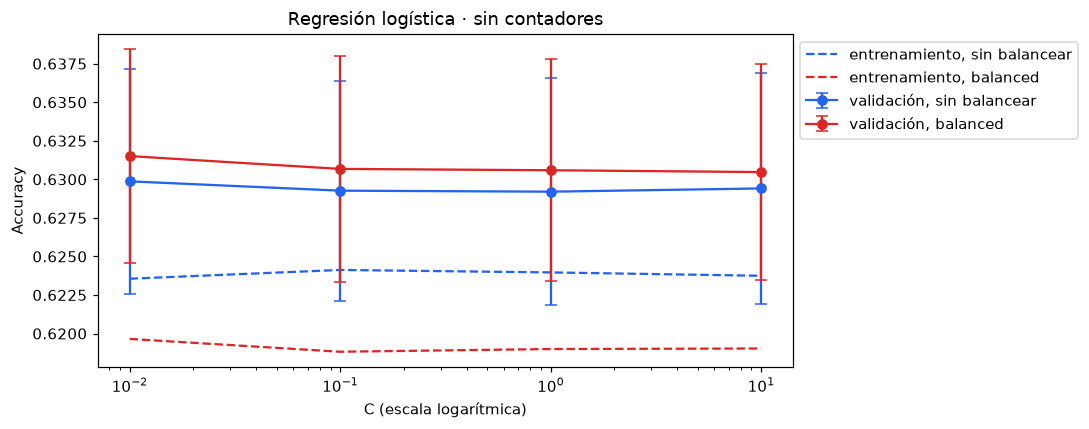

In [ ]:
graficar_grilla('regresión logística', 'clasificador__C', 'clasificador__class_weight',
                 ['sin balancear', 'balanced'], 'C (escala logarítmica)', escala='log')

**Conclusión:** agregar winrate de 20 da el mejor promedio (63,16 %), pero «sin contadores» queda prácticamente igual (63,15 %) con 9 columnas menos. Por la regla elegimos **sin contadores**. Quitar Elo baja a 62,37 %; los demás cambios son pequeños.

La curva de `C` queda casi plana. Balancear apenas cambia la accuracy, pero reparte mejor los aciertos: con `C = 0,01`, el recall de A pasa de 73,3 % a 65,6 %, y el de B sube de 51,3 % a 60,4 %.

### 8.2 Árbol de decisión

Agregamos el árbol de Berducci y lo hacemos pasar por las mismas nueve variantes de columnas. Su grilla combina 6 profundidades, 3 mínimos de muestras por hoja y 2 opciones de balance. La curva cambia la profundidad y mantiene el mínimo por hoja elegido en esa variante.

In [ ]:
familia = 'árbol de decisión'
tablas_por_familia[familia] = buscar_familia(familia)
display(tablas_por_familia[familia][['columnas', 'accuracy', 'desvío', 'accuracy train',
                                     'diferencia con base', 'folds que mejoran']].round(4))
mostrar_grillas(familia)

,columnas,accuracy,desvío,accuracy train,diferencia con base,folds que mejoran
variante,,,,,,
base (27 de la E2),27,0.6237,0.0097,0.6128,0.0000,0
sin Elo,26,0.6074,0.0085,0.6173,-0.0163,0
sin ranking,26,0.6243,0.0107,0.6194,0.0006,3
agregamos winrate 20,28,0.6237,0.0097,0.6128,0.0000,0
winrate 20 en vez de rondas,27,0.6237,0.0097,0.6128,0.0000,0
sin H2H,25,0.6237,0.0097,0.6128,0.0000,0
sin estabilidad,24,0.6237,0.0097,0.6128,0.0000,0
sin contadores,18,0.6237,0.0097,0.6128,0.0000,0
historia sin log,27,0.6237,0.0097,0.6128,0.0000,0


param_clasificador__class_weight,param_clasificador__max_depth,param_clasificador__min_samples_leaf,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
balanced,3,50,0.623721,0.009687,0.612814,0.616982,0.705324,0.530533,1
balanced,3,200,0.623621,0.010197,0.612171,0.617018,0.704989,0.530722,2
balanced,3,1,0.623432,0.009788,0.612975,0.616672,0.705380,0.529864,3
None,3,50,0.622595,0.009843,0.613478,0.616913,0.692200,0.543464,4
None,3,200,0.622495,0.010334,0.612835,0.616949,0.691864,0.543654,5
None,3,1,0.622306,0.009909,0.613639,0.616602,0.692255,0.542796,6
None,8,200,0.621702,0.006645,0.631259,0.616672,0.685664,0.548416,7
None,10,200,0.621391,0.006646,0.632737,0.615805,0.693659,0.538929,8
None,14,200,0.621391,0.006646,0.632737,0.615805,0.693659,0.538929,8
None,4,200,0.620766,0.009708,0.617420,0.610246,0.732225,0.493065,10


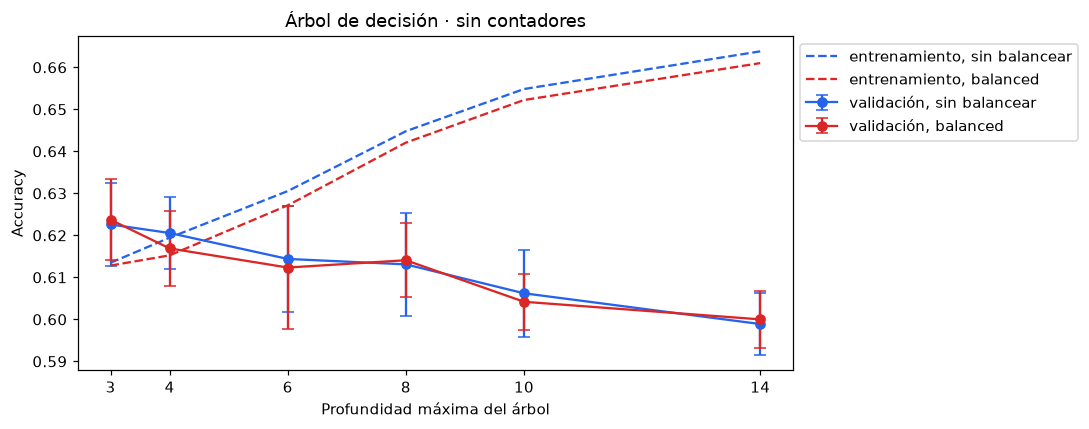

In [ ]:
graficar_grilla('árbol de decisión', 'clasificador__max_depth', 'clasificador__class_weight',
                 ['sin balancear', 'balanced'], 'Profundidad máxima del árbol')

**Conclusión:** la mejor media aparece sin ranking (62,43 %). Sin los nueve contadores queda en 62,37 %, dentro del margen y con 18 columnas. Por eso elegimos **sin contadores**. Quitar Elo baja a 60,74 %.

El representante del árbol tiene **3 niveles**, un mínimo de **50 series por hoja** y `balanced`. Varias quitas dan el mismo resultado. En la curva, aumentar la profundidad mejora el entrenamiento pero empeora la validación: las configuraciones más profundas no aportaron una mejora en estas pruebas.

### 8.3 Random forest

Variamos profundidad, mínimo de muestras por hoja, variables consideradas en cada división y balance de clases. La curva compara profundidades 6 y 12, con y sin balancear. Mantiene `min_samples_leaf = 10` y `max_features = 'sqrt'`, los valores elegidos en la variante sin contadores. El bosque usa 150 árboles.

In [ ]:
familia = 'random forest'
tablas_por_familia[familia] = buscar_familia(familia)
display(tablas_por_familia[familia][['columnas', 'accuracy', 'desvío', 'accuracy train',
                                     'diferencia con base', 'folds que mejoran']].round(4))
mostrar_grillas(familia)

,columnas,accuracy,desvío,accuracy train,diferencia con base,folds que mejoran
variante,,,,,,
base (27 de la E2),27,0.6349,0.0071,0.6799,0.0000,0
sin Elo,26,0.6242,0.0047,0.6780,-0.0108,0
sin ranking,26,0.6310,0.0094,0.6396,-0.0039,1
agregamos winrate 20,28,0.6329,0.0074,0.6789,-0.0020,1
winrate 20 en vez de rondas,27,0.6329,0.0074,0.6788,-0.0020,1
sin H2H,25,0.6333,0.0074,0.7357,-0.0016,0
sin estabilidad,24,0.6325,0.0074,0.6777,-0.0024,1
sin contadores,18,0.6329,0.0082,0.7141,-0.0020,2
historia sin log,27,0.6350,0.0071,0.6799,0.0001,2


param_clasificador__class_weight,param_clasificador__max_depth,param_clasificador__max_features,param_clasificador__min_samples_leaf,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
None,12,sqrt,30,0.634916,0.007092,0.679931,0.626983,0.730463,0.526051,1
None,12,sqrt,10,0.633886,0.005749,0.735603,0.626119,0.728441,0.526081,2
balanced,12,sqrt,30,0.633236,0.006450,0.680243,0.631422,0.656390,0.606690,3
None,6,sqrt,30,0.632136,0.007755,0.641227,0.621927,0.746486,0.501798,4
None,6,sqrt,10,0.631759,0.007797,0.645671,0.621587,0.745758,0.501866,5
balanced,6,sqrt,10,0.631547,0.006497,0.645696,0.629427,0.660446,0.598394,6
None,12,0.7,30,0.630555,0.006382,0.700195,0.623900,0.713818,0.535581,7
balanced,6,sqrt,30,0.630280,0.008051,0.640561,0.628273,0.657770,0.598704,8
None,12,0.7,10,0.630189,0.007840,0.768679,0.623623,0.712685,0.536064,9
None,6,0.7,30,0.630010,0.007606,0.643439,0.622509,0.721843,0.525328,10


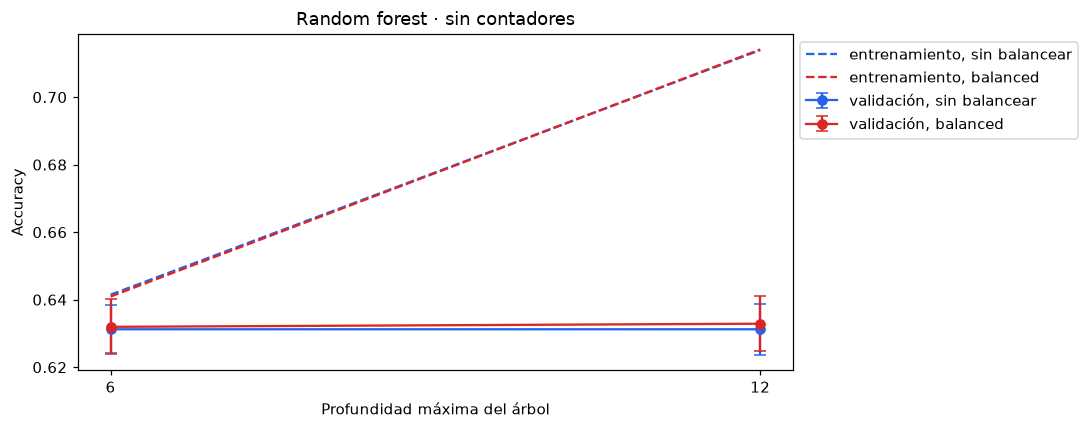

In [ ]:
graficar_grilla('random forest', 'clasificador__max_depth', 'clasificador__class_weight',
                 ['sin balancear', 'balanced'], 'Profundidad máxima del árbol')

**Conclusión:** la mejor media aparece sin log (63,50 %), casi igual a la base (63,49 %). «Sin contadores» da 63,29 % y entra en el margen definido, con 18 columnas. Esa es la variante que llevamos a la comparación final. Sin Elo baja a 62,42 %.

El bosque elegido tiene profundidad 12, un mínimo de 10 muestras por hoja, `max_features = 'sqrt'` y `balanced`. Acierta 71,41 % en entrenamiento y 63,29 % en validación: esa diferencia es una señal de posible sobreajuste.

### 8.4 Gradient boosting

Variamos tasa de aprendizaje, cantidad de iteraciones, hojas y regularización. La curva compara 100 y 200 iteraciones con tasas de 0,05 y 0,1. Mantiene `max_leaf_nodes = 7` y `l2_regularization = 1`, los valores elegidos en la variante sin contadores. No usamos corte temprano con una partición interna al azar.

In [ ]:
familia = 'gradient boosting'
tablas_por_familia[familia] = buscar_familia(familia)
display(tablas_por_familia[familia][['columnas', 'accuracy', 'desvío', 'accuracy train',
                                     'diferencia con base', 'folds que mejoran']].round(4))
mostrar_grillas(familia)

,columnas,accuracy,desvío,accuracy train,diferencia con base,folds que mejoran
variante,,,,,,
base (27 de la E2),27,0.6327,0.0071,0.6391,0.0000,0
sin Elo,26,0.6232,0.0054,0.6354,-0.0095,0
sin ranking,26,0.6301,0.0086,0.6340,-0.0026,2
agregamos winrate 20,28,0.6321,0.0067,0.6393,-0.0006,1
winrate 20 en vez de rondas,27,0.6311,0.0067,0.6384,-0.0016,2
sin H2H,25,0.6320,0.0075,0.6387,-0.0006,2
sin estabilidad,24,0.6321,0.0066,0.6387,-0.0006,1
sin contadores,18,0.6313,0.0120,0.6467,-0.0013,3
historia sin log,27,0.6327,0.0071,0.6391,0.0000,0


param_clasificador__l2_regularization,param_clasificador__learning_rate,param_clasificador__max_iter,param_clasificador__max_leaf_nodes,mean_test_accuracy,std_test_accuracy,mean_train_accuracy,mean_test_f1_macro,mean_test_recall_A,mean_test_recall_B,rank_test_accuracy
0.0,0.05,100,7,0.632673,0.007088,0.639075,0.626851,0.709934,0.544612,1
1.0,0.05,100,7,0.631992,0.007112,0.638816,0.626003,0.710708,0.542355,2
1.0,0.10,100,7,0.629839,0.008993,0.651373,0.624307,0.703414,0.545931,3
0.0,0.05,200,7,0.629451,0.009809,0.651817,0.623952,0.702850,0.545774,4
1.0,0.05,200,7,0.629441,0.009543,0.651488,0.623994,0.702584,0.546092,5
0.0,0.10,100,7,0.629057,0.011592,0.652606,0.623350,0.704017,0.543669,6
1.0,0.05,100,15,0.628607,0.008853,0.661089,0.622493,0.708082,0.538082,7
0.0,0.05,100,15,0.628259,0.009643,0.661094,0.621868,0.709853,0.535283,8
1.0,0.05,200,15,0.625396,0.011139,0.688574,0.619720,0.700529,0.539793,9
1.0,0.10,200,7,0.625339,0.014735,0.675078,0.619595,0.699643,0.540558,10


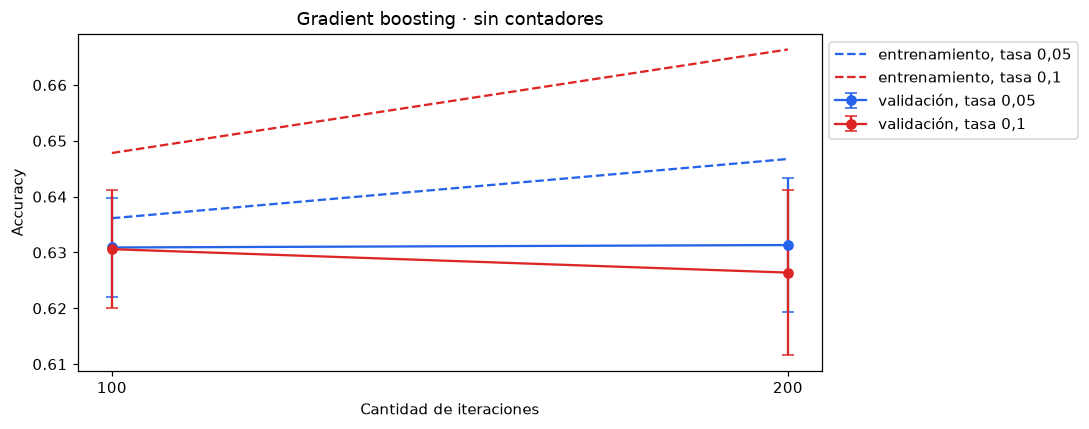

In [ ]:
graficar_grilla('gradient boosting', 'clasificador__max_iter', 'clasificador__learning_rate',
                 ['tasa 0,05', 'tasa 0,1'], 'Cantidad de iteraciones')

**Conclusión:** la base obtiene 63,27 %. Sin los 9 contadores queda en 63,13 %: pierde 0,13 puntos y entra en el margen, por lo que elegimos la variante de **18 columnas**. Quitar Elo baja a 62,32 %.

La configuración elegida usa tasa 0,05, 200 iteraciones, 7 hojas y regularización L2 de 1. En entrenamiento da 64,67 %, más cerca de su validación que el bosque. Aun así, varía más entre períodos: su desvío es de 1,20 puntos.

In [ ]:
tabla_variantes = pd.concat(tablas_por_familia, names=['familia', 'variante'])
assert len(tabla_variantes) == len(clasificadores) * len(variantes)
assert all(np.isfinite(b.cv_results_['mean_test_accuracy']).all() for b in busquedas.values())

**Lectura conjunta de las columnas:** cada variante vuelve a ajustar sus hiperparámetros. Por eso comparamos configuraciones completas, no el efecto aislado de quitar una variable. Tampoco combinamos quitas que no medimos juntas.

### 8.5 El winrate de 20 donde faltan las rondas

Hay **2.635 series del entrenamiento (7,6 %)** con winrate de partidos pero sin winrate de rondas. Las medimos por separado en las cuatro familias. Cada variante usa los parámetros elegidos con la validación completa; este grupo no decide al ganador.

In [ ]:
subgrupo = X_train.round_winrate_last20_advantage_a.isna() & X_train[EXTRA].notna()
filas_cobertura = []
for familia, clf in clasificadores.items():
    for fold, (e, v) in enumerate(cv, 1):
        v_sub = v[subgrupo.iloc[v].to_numpy()]
        fila = {'familia': familia, 'fold': fold, 'series': len(v_sub)}
        assert len(v_sub) > 0
        for nombre in [BASE, 'agregamos winrate 20']:
            columnas, usar_log = variantes[nombre]
            parametros = tabla_variantes.loc[(familia, nombre), 'parámetros']
            modelo = armar(clf, columnas, usar_log).set_params(**parametros)
            modelo.fit(X_train.iloc[e], y_train.iloc[e])
            fila[nombre] = accuracy_score(y_train.iloc[v_sub], modelo.predict(X_train.iloc[v_sub]))
        fila['diferencia'] = fila['agregamos winrate 20'] - fila[BASE]
        filas_cobertura.append(fila)
tabla_cobertura = pd.DataFrame(filas_cobertura)
display(tabla_cobertura.set_index(['familia', 'fold']).round(4))

series  base (27 de la E2)  agregamos winrate 20  \
familia             fold                                                     
regresión logística 1        530              0.5849                0.5925   
                    2        576              0.6059                0.5990   
                    3        400              0.6825                0.6600   
                    4        208              0.6635                0.6779   
                    5        143              0.6713                0.6643   
árbol de decisión   1        530              0.5811                0.5811   
                    2        576              0.5990                0.5990   
                    3        400              0.6125                0.6125   
                    4        208              0.6587                0.6587   
                    5        143              0.6294                0.6294   
random forest       1        530              0.6019                0.6000   
                    2        576              0.6337                0.6128   
                    3        400              0.6675                0.6700   
                    4        208              0.6923                0.6827   
                    5        143              0.6573                0.6573   
gradient boosting   1        530              0.5981                0.5981   
                    2        576              0.6250                0.6198   
                    3        400              0.6825                0.6825   
                    4        208              0.6587                0.6731   
                    5        143              0.6573                0.6364   

                          diferencia  
familia             fold              
regresión logística 1         0.0075  
                    2        -0.0069  
                    3        -0.0225  
                    4         0.0144  
                    5        -0.0070  
árbol de decisión   1         0.0000  
                    2         0.0000  
                    3         0.0000  
                    4         0.0000  
                    5         0.0000  
random forest       1        -0.0019  
                    2        -0.0208  
                    3         0.0025  
                    4        -0.0096  
                    5         0.0000  
gradient boosting   1         0.0000  
                    2        -0.0052  
                    3         0.0000  
                    4         0.0144  
                    5        -0.0210

**Conclusión:** agregar winrate de 20 no muestra una mejora consistente en las series sin rondas:

- **Logística:** baja 0,29 puntos en promedio; mejora en 2 de los 5 folds.
- **Árbol de decisión:** no cambia el resultado en ninguno de los 5 folds.
- **Random forest:** baja 0,60 puntos; mejora en 1 de los 5 folds.
- **Gradient boosting:** baja 0,24 puntos; mejora en 1 de los 5 folds.

Tener ese dato en más partidos no alcanzó para mejorar el resultado de este grupo.

## 9. Comparación final: el mejor representante de cada familia

Recién ahora elegimos. Dentro de cada familia aplicamos la regla de menos columnas con rendimiento cercano al mejor. Después comparamos sus cuatro representantes y, si la diferencia es chica, preferimos el más simple.

Las barras muestran media ± desvío entre los 5 períodos. También dejamos los cinco resultados a la vista. El desvío no es un intervalo de confianza.

In [ ]:
representantes = []
for familia in clasificadores:
    t = tabla_variantes.loc[familia]
    mejor_variante = t.accuracy.idxmax()
    limite = t.loc[mejor_variante, 'accuracy'] - t.loc[mejor_variante, 'desvío']
    candidatas = t[t.accuracy >= limite].sort_values(
        ['columnas', 'accuracy'], ascending=[True, False], kind='stable')
    nombre = candidatas.index[0]
    fila = candidatas.iloc[0].to_dict()
    fila.update({'familia': familia, 'variante': nombre, 'límite columnas': limite})
    representantes.append(fila)
tabla_modelos = pd.DataFrame(representantes).set_index('familia')
mejor_familia = tabla_modelos.accuracy.idxmax()
limite_familias = tabla_modelos.loc[mejor_familia, 'accuracy'] - tabla_modelos.loc[mejor_familia, 'desvío']
FAMILIA = next(f for f in clasificadores if tabla_modelos.loc[f, 'accuracy'] >= limite_familias)
VARIANTE = tabla_modelos.loc[FAMILIA, 'variante']
COLUMNAS_FINAL, USAR_LOG = variantes[VARIANTE]
PARAMETROS_FINAL = tabla_modelos.loc[FAMILIA, 'parámetros']
fila_ganadora = tabla_modelos.loc[FAMILIA]
display(tabla_modelos[['variante', 'columnas', 'accuracy', 'desvío',
                      'accuracy train', 'f1 macro', 'recall A', 'recall B']].round(4))
display(pd.DataFrame({f: parametros_cortos(tabla_modelos.loc[f, 'parámetros'])
                      for f in clasificadores}).T.fillna('—'))
accuracy_folds = pd.DataFrame({
    f: resultados_variantes[f, tabla_modelos.loc[f, 'variante']] for f in clasificadores},
    index=pd.Index(range(1, N_SPLITS+1), name='fold'))
accuracy_folds.insert(0, 'piso', resultados_piso['test_accuracy'])
display(accuracy_folds.round(4))

,variante,columnas,accuracy,desvío,accuracy train,f1 macro,recall A,recall B
familia,,,,,,,,
regresión logística,sin contadores,18,0.6315,0.0069,0.6197,0.6297,0.6559,0.6035
árbol de decisión,sin contadores,18,0.6237,0.0097,0.6128,0.6170,0.7053,0.5305
random forest,sin contadores,18,0.6329,0.0082,0.7141,0.6305,0.6665,0.5944
gradient boosting,sin contadores,18,0.6313,0.0120,0.6467,0.6251,0.7132,0.5380


,C,class_weight,max_depth,min_samples_leaf,max_features,l2_regularization,learning_rate,max_iter,max_leaf_nodes
regresión logística,0.01,balanced,—,—,—,—,—,—,—
árbol de decisión,—,balanced,3,50,—,—,—,—,—
random forest,—,balanced,12,10,sqrt,—,—,—,—
gradient boosting,—,—,—,—,—,1.0,0.05,200.0,7.0


,piso,regresión logística,árbol de decisión,random forest,gradient boosting
fold,,,,,
1,0.5283,0.6267,0.6077,0.6209,0.6093
2,0.5239,0.6208,0.6209,0.6290,0.6332
3,0.5350,0.6385,0.6281,0.6323,0.6316
4,0.5395,0.6329,0.6246,0.6365,0.6373
5,0.5367,0.6387,0.6373,0.6457,0.6452


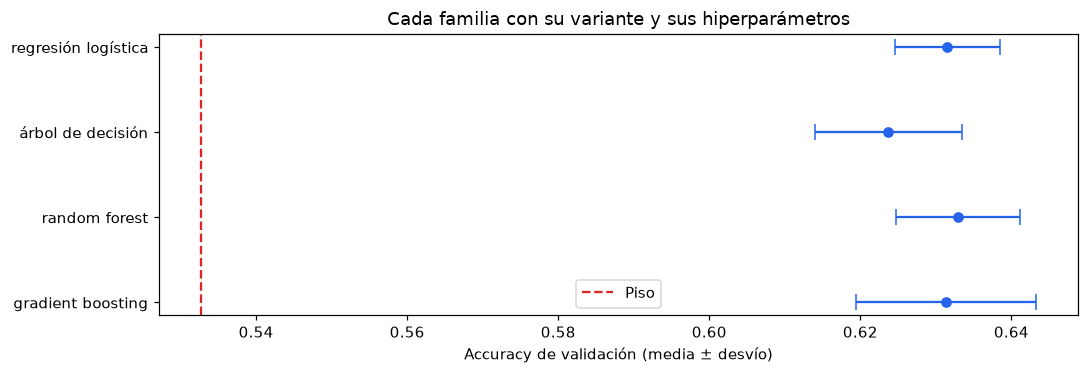

,familia,class_weight,accuracy,recall A,recall B
0,regresión logística,None,0.6299,0.7327,0.5128
1,regresión logística,balanced,0.6315,0.6559,0.6035
2,random forest,None,0.6312,0.7291,0.5196
3,random forest,balanced,0.6329,0.6665,0.5944


In [ ]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.errorbar(tabla_modelos.accuracy, tabla_modelos.index, xerr=tabla_modelos['desvío'],
            fmt='o', color='#2563eb', capsize=5)
ax.axvline(resumen_piso['accuracy'], color='#dc2626', linestyle='--', label='Piso')
ax.set(xlabel='Accuracy de validación (media ± desvío)',
       title='Cada familia con su variante y sus hiperparámetros')
ax.invert_yaxis(); ax.legend(); plt.tight_layout(); plt.show()

# Balance de clases: comparar sin cambiar los otros parámetros del finalista.
balance = []
for familia in ['regresión logística', 'random forest']:
    nombre = tabla_modelos.loc[familia, 'variante']
    b = busquedas[familia, nombre]
    r = b.cv_results_
    elegidos = tabla_modelos.loc[familia, 'parámetros']
    for i, p in enumerate(r['params']):
        if all(p[k] == valor for k, valor in elegidos.items() if k != 'clasificador__class_weight'):
            balance.append({'familia': familia, 'class_weight': str(p['clasificador__class_weight']),
                            'accuracy': r['mean_test_accuracy'][i],
                            'recall A': r['mean_test_recall_A'][i], 'recall B': r['mean_test_recall_B'][i]})
display(pd.DataFrame(balance).round(4))

**Conclusión:** las cuatro familias llegan con la variante sin contadores, de 18 columnas:

| Modelo ajustado | Accuracy de validación | Desvío entre folds |
|---|---:|---:|
| Logística | 63,15 % | 0,69 puntos |
| Árbol de decisión | 62,37 % | 0,97 puntos |
| Random forest | 63,29 % | 0,82 puntos |
| Gradient boosting | 63,13 % | 1,20 puntos |

**Nos quedamos con la logística.** El bosque mejora apenas 0,14 puntos, dentro del margen de la regla, y tiene una brecha mayor entre entrenamiento y validación. El árbol y el boosting no superan su promedio. Esto vale para las configuraciones probadas; no demuestra que ningún otro modelo pueda mejorar.

## 10. Lo que congelamos antes de mirar el test

Desde acá no cambiamos nada más. Esta es la configuración final, elegida solo con validación cruzada sobre el entrenamiento:

In [ ]:
modelo_final = armar(clasificadores[FAMILIA], COLUMNAS_FINAL, USAR_LOG).set_params(**PARAMETROS_FINAL)
modelo_final.fit(X_train, y_train)
congelado = pd.DataFrame([
    ('Métrica principal', 'accuracy'),
    ('Piso', 'DummyClassifier (clase más frecuente)'),
    ('Modelo', FAMILIA), ('Variante de columnas', VARIANTE),
    ('Cantidad de columnas originales', len(COLUMNAS_FINAL)),
    ('log1p en matches_prior', 'sí' if USAR_LOG else 'no'),
    *[(k, str(v)) for k, v in parametros_cortos(PARAMETROS_FINAL).items()],
    ('Umbral', UMBRAL),
    ('Accuracy en validación', f'{fila_ganadora.accuracy:.4f} ± {fila_ganadora["desvío"]:.4f}'),
    ('Validación', f'{N_SPLITS} folds temporales por días'),
    ('Corte del test', f'{CORTE_TEST:%d/%m/%Y}'), ('Semilla', SEMILLA),
], columns=['Decisión', 'Valor']).set_index('Decisión')
display(congelado)
display(pd.DataFrame({'columna del modelo final': COLUMNAS_FINAL}, index=range(1, len(COLUMNAS_FINAL)+1)))
assert 'target_team_a_won' not in COLUMNAS_FINAL
assert set(COLUMNAS_FINAL).issubset(X_train.columns)

,Valor
Decisión,
Métrica principal,accuracy
Piso,DummyClassifier (clase más frecuente)
Modelo,regresión logística
Variante de columnas,sin contadores
Cantidad de columnas originales,18
log1p en matches_prior,sí
C,0.01
class_weight,balanced
Umbral,0.5


,columna del modelo final
1,bo_type
2,tier
3,elo_advantage_a
4,ranking_score_advantage_a
5,round_winrate_last20_advantage_a
6,form_last5_advantage_a
7,same_bo_winrate_last20_advantage_a
8,same_tier_winrate_last20_advantage_a
9,lineup_stability_last5_advantage_a
10,h2h_team_a_winrate_last5


## 11. El modelo final, leído

A partir de acá **el modelo ya no cambia**. Lo que sigue no son pruebas para elegir: es leer el modelo terminado, que es lo que pide la consigna, en tres partes:

1. **Cuánto acierta:** lo medimos una sola vez sobre el test (esta sección).
2. **Dónde se equivoca:** matrices de confusión, errores por tipo de partido y un error concreto (11.1 y 11.2).
3. **En qué se apoya:** importancia por permutación y lectura del clasificador (sección 12).

Usamos las predicciones del test para entender al modelo, nunca para cambiarlo.

In [ ]:
proba_test = modelo_final.predict_proba(X_test)[:, 1]
assert UMBRAL == 0.50
pred_test = modelo_final.predict(X_test)  # Misma decisión y desempate que en validación.
piso = armar(DummyClassifier(strategy='most_frequent'), COLUMNAS_FINAL).fit(X_train, y_train)
tabla_test = pd.DataFrame({'piso': metricas(y_test, piso.predict(X_test)),
                           'modelo final': metricas(y_test, pred_test)}).T
display(tabla_test.round(4))
reporte = pd.DataFrame(classification_report(y_test, pred_test, target_names=['gana B', 'gana A'],
                                             output_dict=True)).T
display(reporte.round(4))

,accuracy,f1 macro
piso,0.5451,0.3528
modelo final,0.6514,0.6485


,precision,recall,f1-score,support
gana B,0.6171,0.6159,0.6165,4012.0000
gana A,0.6800,0.6811,0.6805,4807.0000
accuracy,0.6514,0.6514,0.6514,0.6514
macro avg,0.6485,0.6485,0.6485,8819.0000
weighted avg,0.6514,0.6514,0.6514,8819.0000


**Conclusión:** en las **8.819 series del test**, el modelo acierta **65,1 %**, frente al 54,5 % del piso: **10,6 puntos más**. En validación daba 63,2 %.

El F1 macro es 0,649. El recall es 68,1 % para A y 61,6 % para B. Sirve como referencia de favorito, pero todavía falla en aproximadamente una de cada tres series: el veto de mapas, el rendimiento del día y los cambios de jugadores no quedan completamente reflejados.

### 11.1 Dónde se equivoca: matrices de confusión

- **Por fila:** de las series que ganó cada equipo, qué parte acertamos. La diagonal es el recall.
- **Por columna:** de las veces que dijimos «gana A» (o «gana B»), qué parte era correcta. La diagonal es la precision.

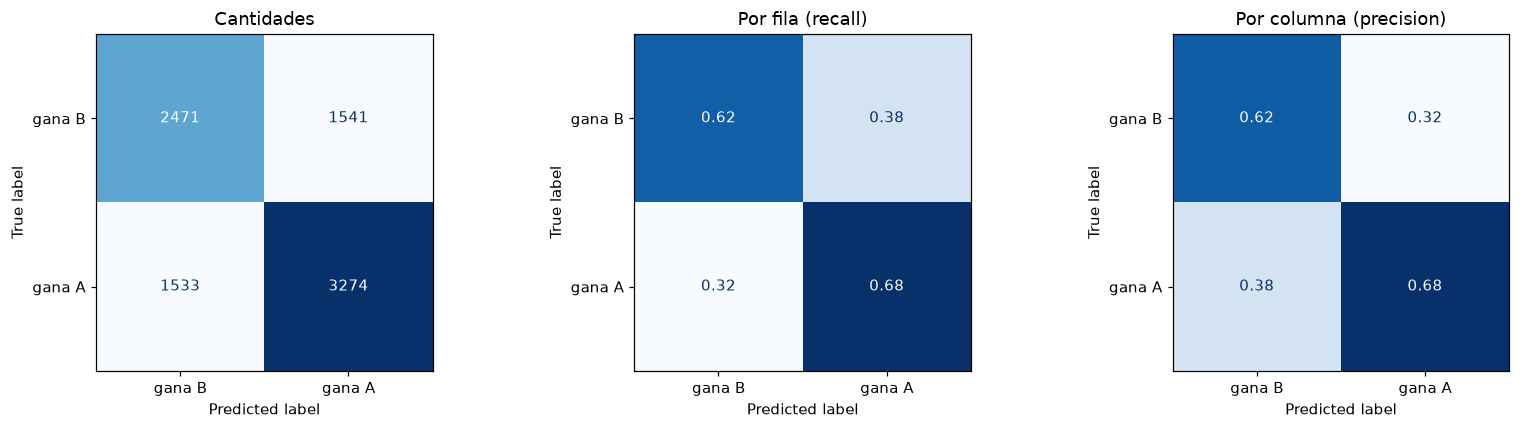

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, norma, titulo in zip(axes, [None, 'true', 'pred'], ['Cantidades', 'Por fila (recall)', 'Por columna (precision)']):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['gana B', 'gana A'], normalize=norma,
                                            values_format='d' if norma is None else '.2f', cmap='Blues',
                                            colorbar=False, ax=ax)
    ax.set_title(titulo)
plt.tight_layout(); plt.show()

**Conclusión:** hay 3.074 errores: en **1.541** ganó B y dijimos A; en **1.533** ganó A y dijimos B. Las cantidades están casi parejas, aunque los recalls no son iguales porque A y B no ganan la misma cantidad de partidos.

Cuando decimos «gana A», acertamos el 68,0 %; cuando decimos «gana B», el 61,7 %. Eso es precision. El recall pregunta cuántas victorias reales de cada lado detectamos.

### 11.2 Dónde y por qué se equivoca

Usamos la presentación de Berducci: gráficos interactivos con fondo oscuro, color turquesa y detalles al pasar el cursor. Vamos de lo general a lo particular: confianza, diferencia de Elo, tipo de partido, evolución mensual, calibración y casos concretos. Las conclusiones quedan en texto y el modelo ya no cambia.

In [ ]:
alt.renderers.enable('html')
ACENTO = '#3fd2d8'
TEXTO = '#e8ecf1'
SUAVE = '#566273'
FONDO = '#0f1318'
ESTILO_ERRORES = {'background': '#0f1318',
 'font': 'Barlow, "Segoe UI", Helvetica, Arial, sans-serif',
 'padding': 10,
 'view': {'continuousWidth': 300, 'continuousHeight': 300, 'stroke': None},
 'axis': {'domainColor': '#2b3440',
          'gridColor': '#1f262f',
          'labelColor': '#9aa5b4',
          'labelFont': 'Barlow, "Segoe UI", Helvetica, Arial, sans-serif',
          'labelFontSize': 13,
          'tickColor': '#2b3440',
          'titleColor': '#9aa5b4',
          'titleFont': 'Barlow, "Segoe UI", Helvetica, Arial, sans-serif',
          'titleFontSize': 13,
          'titleFontWeight': 'normal'},
 'legend': {'labelColor': '#e8ecf1',
            'labelFontSize': 13,
            'titleColor': '#9aa5b4',
            'titleFontSize': 13,
            'titleFontWeight': 'normal'},
 'header': {'labelColor': '#e8ecf1',
            'labelFontSize': 13,
            'titleColor': '#9aa5b4',
            'titleFontSize': 13},
 'text': {'color': '#e8ecf1', 'font': 'Barlow, "Segoe UI", Helvetica, Arial, sans-serif'},
 'title': {'anchor': 'start',
           'fontSize': 19,
           'font': 'Rajdhani, "Arial Narrow", "Segoe UI", sans-serif',
           'fontWeight': 700,
           'color': '#e8ecf1',
           'subtitleColor': '#9aa5b4',
           'subtitleFontSize': 13,
           'subtitleFont': 'Barlow, "Segoe UI", Helvetica, Arial, sans-serif',
           'offset': 12}}
GRAFICOS_ERRORES = {}

def mostrar_grafico_error(nombre, grafico):
    grafico = grafico.configure(**ESTILO_ERRORES)
    GRAFICOS_ERRORES[nombre] = grafico
    display(grafico)

In [ ]:
columnas_detalle = ['match_id', 'start_at_utc', 'team_a_name', 'team_b_name',
    'tournament_name', 'bo_type', 'tier', 'team_a_matches_prior', 'team_b_matches_prior',
    'elo_advantage_a', 'team_a_matches_last30d', 'team_b_matches_last30d',
    'post_team_a_maps_won', 'post_team_b_maps_won']
detalle = test[columnas_detalle].copy()
detalle['real'] = y_test.to_numpy()
detalle['predicho'] = pred_test
detalle['prob. gana A'] = proba_test
detalle['acierto'] = detalle.real.eq(detalle.predicho)
detalle['confianza'] = np.maximum(proba_test, 1 - proba_test)
detalle['historia'] = np.where(detalle[['team_a_matches_prior', 'team_b_matches_prior']].min(axis=1) < 5,
                               'historia corta', 'los dos con 5 o más')
detalle['dif_elo_abs'] = detalle.elo_advantage_a.abs()
comparables = detalle.elo_advantage_a.notna() & detalle.elo_advantage_a.ne(0)
detalle['sorpresa'] = np.nan
detalle.loc[comparables, 'sorpresa'] = detalle.loc[comparables, 'real'].ne(
    detalle.loc[comparables, 'elo_advantage_a'].gt(0).astype(int)).astype(float)
detalle['mes'] = detalle.start_at_utc.dt.strftime('%Y-%m')
detalle['favorito_sin_partidos_30d'] = np.where(detalle.predicho.eq(1),
    detalle.team_a_matches_last30d, detalle.team_b_matches_last30d) == 0
detalle['favorito'] = np.where(detalle.predicho.eq(1), detalle.team_a_name, detalle.team_b_name)
detalle['ganador'] = np.where(detalle.real.eq(1), detalle.team_a_name, detalle.team_b_name)
errores = detalle.loc[~detalle.acierto].copy()
errores['confianza en el error'] = errores.confianza

#### 1. Por confianza

La confianza es la probabilidad que el modelo asignó a su favorito. Las barras muestran cuánto acertó realmente en cada tramo; la rayita blanca muestra la probabilidad media estimada. Dentro de las barras queda la cantidad de series.

In [ ]:
ETIQUETAS_CONFIANZA = ['50–55 %', '55–60 %', '60–65 %', '65–70 %',
                       '70–75 %', '75–80 %', '80 % o más']
detalle['tramo_confianza'] = pd.cut(detalle.confianza,
    [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, np.nextafter(1.0, 2.0)],
    labels=ETIQUETAS_CONFIANZA, right=False)
assert detalle.tramo_confianza.notna().all()
tabla_confianza = detalle.groupby('tramo_confianza', observed=False).agg(
    series=('acierto', 'size'), probabilidad_media=('confianza', 'mean'), accuracy=('acierto', 'mean'),
    aciertos=('acierto', 'sum'))
tabla_confianza['errores'] = tabla_confianza.series - tabla_confianza.aciertos
display(tabla_confianza.round(3))
datos_confianza = tabla_confianza.reset_index().rename(
    columns={'tramo_confianza': 'tramo', 'probabilidad_media': 'confianza'})
datos_confianza['texto'] = datos_confianza.accuracy.map(lambda x: f'{100*x:.0f} %')
datos_confianza['texto_n'] = datos_confianza.series.map(lambda n: f'n = {n:,}'.replace(',', '.'))
base = alt.Chart(datos_confianza).encode(
    x=alt.X('tramo:O', sort=ETIQUETAS_CONFIANZA, axis=alt.Axis(labelAngle=0),
            title='Probabilidad que el modelo le dio a su favorito'))
barras = base.mark_bar(color=ACENTO, cornerRadiusEnd=3, size=72).encode(
    y=alt.Y('accuracy:Q', scale=alt.Scale(domain=[0, 1]), axis=alt.Axis(format='.0%'),
            title='Series acertadas en el test'),
    tooltip=[alt.Tooltip('tramo:O', title='Confianza'), alt.Tooltip('series:Q', title='Series', format=','),
             alt.Tooltip('accuracy:Q', title='Acierta', format='.1%'),
             alt.Tooltip('confianza:Q', title='Confianza media del modelo', format='.1%')])
marca = base.mark_tick(color=TEXTO, thickness=3, size=72).encode(y='confianza:Q')
porcentajes = base.mark_text(color=TEXTO, dy=-9, fontSize=13, fontWeight='bold').encode(
    y='accuracy:Q', text='texto:N')
cantidades = base.mark_text(color=FONDO, y=288, fontSize=11).encode(text='texto_n:N')
grafico = (barras + marca + porcentajes + cantidades).properties(width=680, height=300,
    title=alt.TitleParams(text='Cuando el modelo duda acierta el 54 %; con confianza alta, el 86 %',
        subtitle=['Las 8.819 series del test, agrupadas por la probabilidad asignada al favorito.',
                  'La rayita blanca indica la probabilidad media estimada en cada tramo.']))
mostrar_grafico_error('confianza', grafico)

,series,probabilidad_media,accuracy,aciertos,errores
tramo_confianza,,,,,
50–55 %,2015,0.525,0.540,1089,926
55–60 %,1593,0.574,0.584,930,663
60–65 %,1442,0.625,0.633,913,529
65–70 %,1279,0.674,0.680,870,409
70–75 %,1047,0.724,0.730,764,283
75–80 %,704,0.774,0.777,547,157
80 % o más,739,0.845,0.855,632,107


alt.LayerChart(...)

**Conclusión:** cuando asigna entre 50 % y 55 % al favorito, acierta el **54,0 %**. Cuando asigna 80 % o más, acierta el **85,5 % en 739 series**. El **51,7 % de los errores** aparece cuando había dado menos de 60 %.

En este test, mayor confianza estuvo asociada con más aciertos. Es un resultado por grupos: no garantiza que cada partido futuro con 80 % tenga exactamente esa frecuencia de victoria.

#### 2. Por diferencia de Elo y sorpresas

Llamamos sorpresa a una victoria del equipo con menor Elo. Los dos paneles separan esas series de las que ganó el de mayor Elo; cada barra muestra aciertos y errores por diferencia de Elo. Los 27 empates de Elo quedan fuera de esta comparación de favoritismo.

In [ ]:
ETIQUETAS_ELO = ['0–50', '50–100', '100–150', '150–200', '200–300', '300–400', '400 o más']
detalle['tramo_elo'] = pd.cut(detalle.dif_elo_abs, [0, 50, 100, 150, 200, 300, 400, np.inf],
                             labels=ETIQUETAS_ELO, right=False)
tabla_elo = detalle.groupby('tramo_elo', observed=False).agg(
    series=('acierto', 'size'), accuracy=('acierto', 'mean'), confianza=('confianza', 'mean'))
con_elo = detalle.loc[comparables].copy()
con_elo['tipo'] = np.where(con_elo.sorpresa.eq(1),
    'Sorpresa (ganó el de menos Elo)', 'Ganó el de más Elo')
con_elo['resultado'] = np.where(con_elo.acierto, 'Acierto', 'Error')
tabla_sorpresas = con_elo.groupby('tipo').agg(
    series=('acierto', 'size'), aciertos=('acierto', 'sum'), accuracy=('acierto', 'mean'))
tabla_sorpresas['errores'] = tabla_sorpresas.series - tabla_sorpresas.aciertos
display(tabla_elo.round(3)); display(tabla_sorpresas.round(3))
# Agregamos antes de dibujar: las barras representan las mismas series con menos datos en el gráfico.
datos_elo = con_elo.groupby(['tramo_elo', 'resultado', 'tipo'], observed=True).size().reset_index(name='series')
grafico = alt.Chart(datos_elo).mark_bar().encode(
    x=alt.X('tramo_elo:O', sort=ETIQUETAS_ELO, axis=alt.Axis(labelAngle=0, labelFontSize=12),
            title='Diferencia de Elo entre los dos equipos (puntos)'),
    y=alt.Y('series:Q', title='Series del test'),
    color=alt.Color('resultado:N', title=None,
        scale=alt.Scale(domain=['Acierto', 'Error'], range=['#3ddc97', '#ff5a5f'])),
    column=alt.Column('tipo:N', title=None,
        sort=['Ganó el de más Elo', 'Sorpresa (ganó el de menos Elo)']),
    tooltip=['tipo:N', 'tramo_elo:O', 'resultado:N', 'series:Q']
).properties(width=380, height=240, title='La mayoría de los errores está del lado de las sorpresas')
mostrar_grafico_error('elo', grafico)

,series,accuracy,confianza
tramo_elo,,,
0–50,2916,0.574,0.565
50–100,2323,0.615,0.610
100–150,1543,0.667,0.669
150–200,983,0.756,0.728
200–300,803,0.816,0.788
300–400,209,0.856,0.856
400 o más,42,0.905,0.919


,series,aciertos,accuracy,errores
tipo,,,,
Ganó el de más Elo,5626,5072,0.902,554
Sorpresa (ganó el de menos Elo),3166,661,0.209,2505


alt.Chart(...)

**Conclusión:** con menos de 50 puntos de diferencia de Elo acertamos el **57,4 %**. A medida que la distancia crece, el modelo suele acertar más; el tramo de 400 o más tiene solo **42 series** y se lee con cuidado.

Entre las series con Elo distinto, el **36,0 %** lo ganó el de menor Elo. Esas sorpresas concentran el **81,9 % de los errores de ese grupo**. Esta lectura posterior describe dónde falla; no permite anticipar por sí sola cada sorpresa.

#### 3. Por tipo de partido

Separamos por tier, formato e historia previa. «Historia corta» significa que al menos un equipo tenía menos de 5 antecedentes registrados. Usamos puntos porque el eje horizontal empieza en 50 %; al pasar el cursor se ve también la cantidad de series.

In [ ]:
filas = []
for variable in ['bo_type', 'tier', 'historia']:
    for valor, grupo in detalle.groupby(variable):
        filas.append({'corte': variable, 'grupo': str(valor), 'series': len(grupo),
                      '% gana A': 100*grupo.real.mean(), '% predice A': 100*grupo.predicho.mean(),
                      '% sorpresas': 100*grupo.sorpresa.mean(), 'accuracy': grupo.acierto.mean(),
                      'f1 macro': f1_score(grupo.real, grupo.predicho, average='macro',
                                           labels=[0, 1], zero_division=0)})
tabla_segmentos = pd.DataFrame(filas)
display(tabla_segmentos.round(3))
grafico = alt.Chart(tabla_segmentos).mark_point(filled=True, size=110, color=ACENTO, opacity=1).encode(
    x=alt.X('accuracy:Q', scale=alt.Scale(domain=[0.5, 0.72]), axis=alt.Axis(format='.0%'),
            title='Accuracy en el test'),
    y=alt.Y('grupo:N', title=None, sort=None),
    row=alt.Row('corte:N', title=None, sort=['tier', 'bo_type', 'historia']),
    tooltip=['corte:N', 'grupo:N', 'series:Q', alt.Tooltip('accuracy:Q', format='.1%'),
             alt.Tooltip('% sorpresas:Q', format='.1f')]
).properties(width=420, height=alt.Step(22),
    title='Accuracy por tipo de partido (el eje empieza en 50 %)').resolve_scale(y='independent')
mostrar_grafico_error('tipos', grafico)

,corte,grupo,series,% gana A,% predice A,% sorpresas,accuracy,f1 macro
0,bo_type,1,1412,57.861,56.941,36.000,0.679,0.672
1,bo_type,3,7345,53.873,54.010,36.030,0.646,0.644
2,bo_type,5,62,53.226,70.968,33.871,0.629,0.606
3,tier,a,273,52.381,49.084,41.026,0.586,0.586
4,tier,b,3165,53.839,54.060,34.801,0.651,0.649
5,tier,c,4881,55.296,55.542,36.824,0.655,0.650
6,tier,s,500,52.200,51.800,33.000,0.660,0.659
7,historia,historia corta,1436,64.345,72.493,37.615,0.672,0.621
8,historia,los dos con 5 o más,7383,52.594,51.117,35.704,0.647,0.647


alt.Chart(...)

**Conclusión:** el menor acierto por tier está en **a: 58,6 % en 273 series**. Por formato, BO1 da 67,9 % y BO3, 64,6 %. BO5 tiene solo 62 series: su 62,9 % debe leerse con cuidado.

En **historia corta**, A gana el 64,3 % y lo predecimos en el 72,5 % de los casos. La accuracy es 67,2 %, pero el F1 macro queda en 0,621: reconocer a ambos ganadores cuesta más de lo que sugiere la accuracy sola. Pocos antecedentes registrados no prueban que el equipo sea nuevo.

#### 4. A lo largo del test

La línea turquesa muestra la accuracy mensual y la punteada, la confianza media. En la tabla también queda la proporción de favoritos sin partidos registrados en los 30 días anteriores. Eso no demuestra que no hayan jugado fuera de nuestra fuente.

In [ ]:
tabla_mensual = detalle.groupby('mes').agg(
    series=('acierto', 'size'), accuracy=('acierto', 'mean'), confianza=('confianza', 'mean'),
    sorpresas=('sorpresa', 'mean'), favorito_inactivo=('favorito_sin_partidos_30d', 'mean'))
display(tabla_mensual.round(3))
mensual = tabla_mensual.reset_index()
mensual['mes'] = pd.to_datetime(mensual.mes + '-01')
base = alt.Chart(mensual).encode(
    x=alt.X('yearmonth(mes):T', title=None, axis=alt.Axis(format='%b %Y', labelFontSize=12)))
aciertos = base.mark_line(point=alt.OverlayMarkDef(color=ACENTO, filled=True), color=ACENTO, strokeWidth=3).encode(
    y=alt.Y('accuracy:Q', scale=alt.Scale(domain=[0.55, 0.72]), axis=alt.Axis(format='.0%'), title='Accuracy'),
    tooltip=[alt.Tooltip('yearmonth(mes):T', title='Mes'), 'series:Q',
             alt.Tooltip('accuracy:Q', format='.1%'), alt.Tooltip('confianza:Q', format='.1%'),
             alt.Tooltip('favorito_inactivo:Q', title='Favorito sin actividad registrada', format='.1%')])
confianza = base.mark_line(strokeDash=[4, 3], color=SUAVE).encode(y='confianza:Q')
grafico = (aciertos + confianza).properties(width=640, height=220,
    title='Accuracy por mes (línea llena) y confianza media (punteada)')
mostrar_grafico_error('meses', grafico)

,series,accuracy,confianza,sorpresas,favorito_inactivo
mes,,,,,
2026-03,1693,0.653,0.652,0.355,0.012
2026-04,1420,0.668,0.646,0.345,0.019
2026-05,1370,0.664,0.635,0.358,0.022
2026-06,697,0.648,0.629,0.357,0.046
2026-07,768,0.600,0.642,0.397,0.091
2026-08,1105,0.660,0.631,0.356,0.045
2026-09,1136,0.630,0.640,0.379,0.035
2026-10,630,0.670,0.659,0.342,0.033


alt.LayerChart(...)

**Conclusión:** el peor mes es **julio: 60,0 % de accuracy en 768 series**. También tiene más favoritos sin partidos registrados en los 30 días anteriores: **9,1 %**, frente al 1,2 % de marzo. La confianza media de julio quedó en 64,2 %, por encima de lo que acertó.

En agosto vuelve a 66,0 % y en octubre llega a 67,0 %. No vemos una caída continua en este período. La coincidencia de julio con estadísticas menos recientes es una pista para investigar, no una causa demostrada.

#### 5. Calibración

Agrupamos la probabilidad de **gana A** en tramos de 10 puntos. La diagonal indica coincidencia entre la estimación y la frecuencia real; los puntos tienen el detalle de cuántas series los sostienen. Brier y log loss complementan esta lectura: menores valores son mejores. La referencia usa siempre la proporción de victorias de A del entrenamiento; no reajustamos las probabilidades con el test.

In [ ]:
detalle['tramo_prob_a'] = pd.cut(detalle['prob. gana A'], np.linspace(0, 1, 11), include_lowest=True)
tabla_calibracion = detalle.groupby('tramo_prob_a', observed=True).agg(
    series=('real', 'size'), probabilidad_media=('prob. gana A', 'mean'), frecuencia_real=('real', 'mean'))
tabla_calibracion['diferencia'] = tabla_calibracion.frecuencia_real - tabla_calibracion.probabilidad_media
probabilidad_piso = np.full(len(y_test), y_train.mean())
tabla_probabilidades = pd.DataFrame({
    'modelo': {'Brier': brier_score_loss(y_test, proba_test), 'log loss': log_loss(y_test, proba_test)},
    'frecuencia del entrenamiento': {'Brier': brier_score_loss(y_test, probabilidad_piso),
                                     'log loss': log_loss(y_test, probabilidad_piso)},
}).T
display(tabla_calibracion.round(3)); display(tabla_probabilidades.round(4))
diagonal = alt.Chart(pd.DataFrame({'x': [0, 1]})).mark_line(color=SUAVE, strokeDash=[4, 3]).encode(
    x='x:Q', y='x:Q')
puntos = alt.Chart(tabla_calibracion.reset_index(drop=True)).mark_line(
    point=alt.OverlayMarkDef(color=ACENTO, filled=True), color=ACENTO, strokeWidth=3).encode(
    x=alt.X('probabilidad_media:Q', title='Probabilidad de «gana A» según el modelo', axis=alt.Axis(format='.0%')),
    y=alt.Y('frecuencia_real:Q', title='Proporción real de series que ganó A', axis=alt.Axis(format='.0%')),
    tooltip=['series:Q', alt.Tooltip('probabilidad_media:Q', title='Estimación', format='.1%'),
             alt.Tooltip('frecuencia_real:Q', title='Frecuencia real', format='.1%')])
grafico = (diagonal + puntos).properties(width=360, height=360,
    title='Calibración en el test: estimación y frecuencia real')
mostrar_grafico_error('calibracion', grafico)

,series,probabilidad_media,frecuencia_real,diferencia
tramo_prob_a,,,,
"(-0.001, 0.1]",22,0.076,0.091,0.015
"(0.1, 0.2]",273,0.162,0.176,0.014
"(0.2, 0.3]",766,0.256,0.304,0.048
"(0.3, 0.4]",1171,0.352,0.364,0.011
"(0.4, 0.5]",1772,0.454,0.465,0.011
"(0.5, 0.6]",1836,0.547,0.583,0.036
"(0.6, 0.7]",1550,0.648,0.670,0.021
"(0.7, 0.8]",985,0.744,0.790,0.046
"(0.8, 0.9]",396,0.836,0.869,0.033


,Brier,log loss
modelo,0.2176,0.6245
frecuencia del entrenamiento,0.2481,0.6894


alt.LayerChart(...)

**Conclusión:** las probabilidades siguen razonablemente la diagonal en este test, aunque A gana algo más seguido de lo estimado en la mayoría de los tramos. Por ejemplo, donde estima **64,8 %** en promedio, A gana el **67,0 %**. En el total estima 51,9 % para A y se observa 54,5 %.

El modelo obtiene **Brier 0,2176** y **log loss 0,6245**, mejores que la referencia constante (0,2481 y 0,6894). Los extremos tienen solo **22 y 48 series**: allí la evidencia es menor. Es un diagnóstico favorable de este período, sin garantizar probabilidades exactas en cada partido ni en el futuro.

#### 6. Casos concretos

Las cinco series donde el modelo se equivocó con más confianza. Los marcadores sirven para leer el resultado, no son predictores.

In [ ]:
columnas_caso = ['start_at_utc', 'team_a_name', 'team_b_name', 'tournament_name', 'bo_type', 'tier',
    'elo_advantage_a', 'team_a_matches_last30d', 'team_b_matches_last30d', 'prob. gana A',
    'favorito', 'ganador', 'post_team_a_maps_won', 'post_team_b_maps_won']
display(errores.sort_values('confianza en el error', ascending=False)[columnas_caso].head(5).round(3))

,start_at_utc,team_a_name,team_b_name,tournament_name,bo_type,tier,elo_advantage_a,team_a_matches_last30d,team_b_matches_last30d,prob. gana A,favorito,ganador,post_team_a_maps_won,post_team_b_maps_won
5697,2026-07-24 15:50:00+00:00,Vitality,Liquid,BLAST Bounty Summer 2026: Closed Qualifier,3,a,461.061,0,0,0.938,Vitality,Liquid,0,2
2695,2026-04-23 17:00:00+00:00,Lilmix,BET-M,ESL Challenger League Season 51: Europe - Cup 4,3,b,-464.306,10,7,0.072,BET-M,Lilmix,2,1
5706,2026-07-24 18:00:00+00:00,FURIA,DENDELE,BLAST Bounty Summer 2026: Closed Qualifier,3,a,545.123,0,0,0.927,FURIA,DENDELE,1,2
3514,2026-05-11 11:58:08+00:00,THUNDER dOWNUNDER,Haunted House,Asian Champions League 2026,3,a,320.131,4,1,0.920,THUNDER dOWNUNDER,Haunted House,0,2
7360,2026-09-09 03:10:00+00:00,The MongolZ,5star,FISSURE Playground 3,3,s,389.446,3,4,0.914,The MongolZ,5star,0,2


**Vitality vs. Liquid, 24/07/2026.** El modelo favorecía a Vitality con una salida de 93,8 %, pero ganó Liquid 2-0. Vitality llegaba con 461 puntos más de Elo, mejor ranking y mejores antecedentes directos.

Ninguno de los dos tenía partidos registrados en los 30 días anteriores. Lo mismo ocurre con FURIA y DENDELE, otro error de ese día y torneo. Las estadísticas podían describir un nivel viejo y no reflejar cambios recientes. Es una explicación posible; el CSV no permite asegurar la causa de esas derrotas.

## 12. En qué se apoya el modelo

**Importancia por permutación:** desordenamos una columna del test y medimos cuánto baja la accuracy. Repetimos 5 veces. Una caída grande indica que el modelo depende de esa columna. Una caída cercana a cero no prueba que sea inútil: otras variables pueden cubrir información parecida.

,columna,baja de accuracy,desvío
2,elo_advantage_a,0.0538,0.0059
3,ranking_score_advantage_a,0.0146,0.0021
11,team_b_matches_prior,0.0099,0.0016
4,round_winrate_last20_advantage_a,0.0076,0.0018
10,team_a_matches_prior,0.0052,0.0009
9,h2h_team_a_winrate_last5,0.0032,0.0011
5,form_last5_advantage_a,0.0024,0.0009
12,team_a_form_trend_5v5,0.0020,0.0012
13,team_b_form_trend_5v5,0.0014,0.0011
8,lineup_stability_last5_advantage_a,0.0012,0.0002


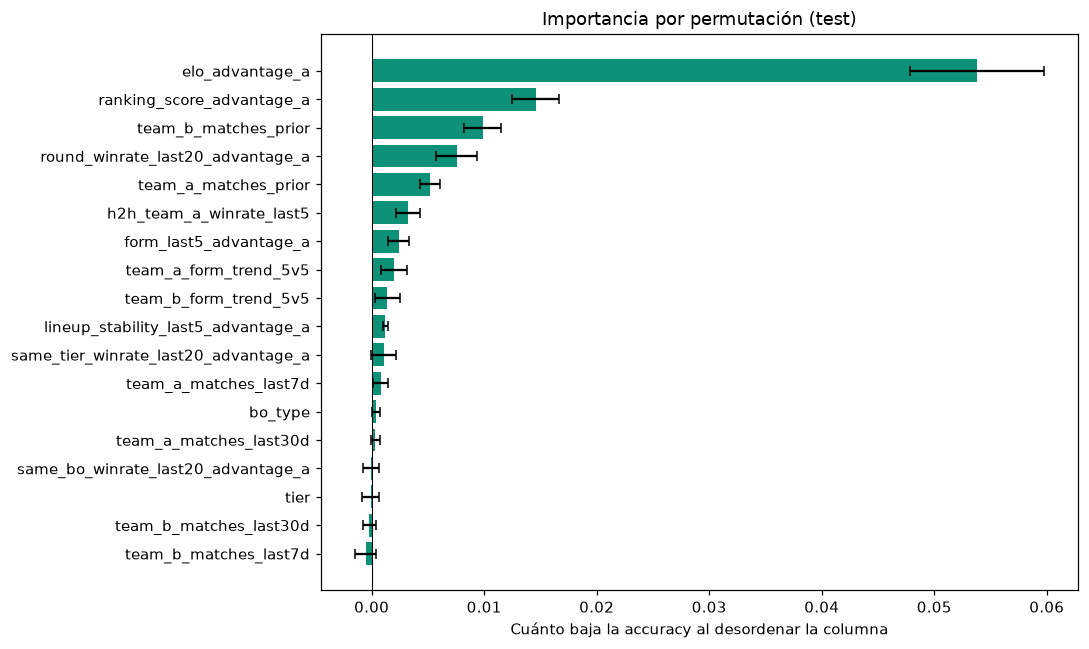

In [ ]:
X_test_final = X_test[COLUMNAS_FINAL]
pi = permutation_importance(modelo_final, X_test_final, y_test, scoring='accuracy',
                            n_repeats=5, random_state=SEMILLA, n_jobs=N_JOBS)
importancias = pd.DataFrame({'columna': COLUMNAS_FINAL, 'baja de accuracy': pi.importances_mean,
                             'desvío': pi.importances_std}).sort_values('baja de accuracy', ascending=False)
display(importancias.round(4))
g = importancias.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(g.columna, g['baja de accuracy'], xerr=g['desvío'], color='#0d9278', capsize=3)
ax.axvline(0, color='black', lw=0.7)
ax.set(xlabel='Cuánto baja la accuracy al desordenar la columna', title='Importancia por permutación (test)')
plt.tight_layout(); plt.show()

**Conclusión:** lo que más usa es **la diferencia de Elo**. Desordenarla baja la accuracy **5,38 puntos**. Después aparecen ranking (1,46), historia de B (0,99), winrate de rondas (0,76) e historia de A (0,52).

Esto mide cuánto depende el modelo de esas columnas, no una causa de ganar. No quitamos variables por esta lectura del test: la selección ya quedó cerrada. Elo tiene sentido como señal principal y lo auditamos con resultados anteriores al partido.

### 12.1 Coeficientes de la logística

Un signo positivo empuja hacia «gana A» y uno negativo hacia «gana B», manteniendo las demás variables fijas. Las numéricas están estandarizadas; las columnas one-hot quedan en 0 y 1.

,variable,coeficiente
0,numericas__elo_advantage_a,0.3855
1,numericas__ranking_score_advantage_a,0.1970
2,historia__team_b_matches_prior,-0.1422
3,numericas__round_winrate_last20_advantage_a,0.1301
4,historia__team_a_matches_prior,0.0931
5,numericas__missingindicator_team_a_form_trend_5v5,-0.0843
6,categoricas__bo_type_5,0.0776
7,numericas__missingindicator_team_b_form_trend_5v5,0.0742
8,numericas__h2h_team_a_winrate_last5,0.0698
9,categoricas__bo_type_3,-0.0517


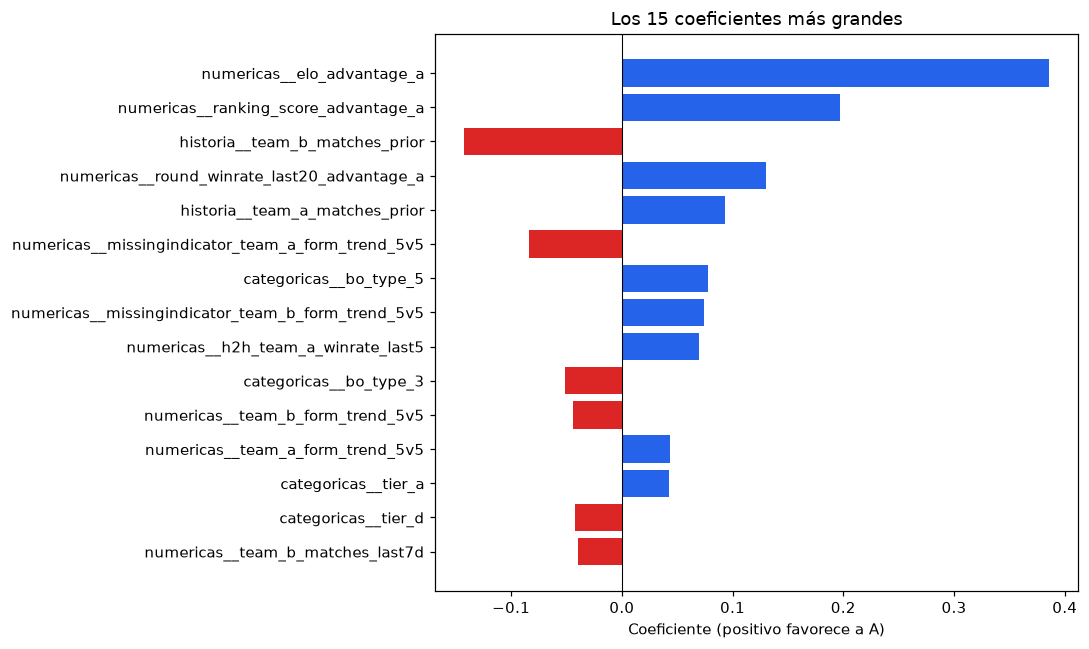

In [ ]:
clf_final = modelo_final['clasificador']
if isinstance(clf_final, LogisticRegression):
    coeficientes = pd.DataFrame({
        'variable': modelo_final['preparar'].get_feature_names_out(),
        'coeficiente': clf_final.coef_[0]})
    coeficientes = coeficientes.reindex(coeficientes.coeficiente.abs().sort_values(ascending=False).index)
    display(coeficientes.round(4).reset_index(drop=True))
    g = coeficientes.head(15).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(g.variable, g.coeficiente, color=np.where(g.coeficiente >= 0, '#2563eb', '#dc2626'))
    ax.axvline(0, color='black', lw=0.7)
    ax.set(xlabel='Coeficiente (positivo favorece a A)', title='Los 15 coeficientes más grandes')
    plt.tight_layout(); plt.show()
else:
    display(pd.Series(parametros_cortos(PARAMETROS_FINAL), name='Configuración elegida').to_frame())

**Conclusión:** más Elo (+0,386) y mejor ranking (+0,197) empujan a favor de A. Más historia previa de B (−0,142) empuja hacia B. Los signos coinciden con el sentido de esas variables.

La forma de los últimos 5 partidos tiene un coeficiente pequeño y negativo. No significa que estar en racha haga perder: el coeficiente se lee manteniendo Elo y las otras señales fijas, y parte de su información ya está representada allí.

**Control de fuga:** las estadísticas basadas en resultados se reconstruyeron usando solo encuentros finalizados antes del inicio. Las 17 restas también coinciden. El CSV no permite reconstruir las mecánicas y alineaciones: para eso hace falta el detalle del Bronze. La captura retrospectiva de la fuente sigue siendo una limitación.

## 13. Conclusión

**Elegimos una regresión logística con 18 columnas**, `C = 0,01` y `class_weight = 'balanced'`. Las cuatro familias pasaron por su propia grilla y las nueve variantes de columnas; son 3.420 ajustes en los folds.

| | Validación temporal | Test |
|---|---:|---:|
| Piso | 53,3 % | 54,5 % |
| Modelo elegido | 63,2 % ± 0,7 puntos | 65,1 % |

El bosque ajustado mejora apenas 0,14 puntos en validación, dentro del margen definido. El árbol y el boosting no lo superan. Preferimos la logística por su simplicidad. Quitar los nueve contadores reduce columnas sin una pérdida clara.

**En qué se apoya y dónde falla.** Predomina Elo, seguido de ranking, historia y rondas. Cuesta más acertar partidos parejos y sorpresas; julio es el peor mes del test. Cuando asigna 80 % o más al favorito, acierta el 85,5 % en ese grupo.

**Las probabilidades.** La curva de calibración acompaña razonablemente las frecuencias de este test, con desviaciones y pocos casos en los extremos. No son garantías individuales. La aplicación debe presentar al modelo como una referencia de favorito, con los límites de sus datos históricos.